# Efficient ViT Inference Through Visual Token Reduction — SigLIP-Base/16

**Question:** how does visual token count (196 / 144 / 100 / 49) affect latency, throughput, GPU memory and compute in the pretrained `google/siglip-base-patch16-224` vision tower?

**Kaggle setup:** *Settings → Accelerator → GPU T4 x2* (only `cuda:0` is used) and *Settings → Internet → On*. Then *Run All* (≈5–10 min).

This notebook is self-contained: it writes `src/*.py`, `README.md` and `requirements.txt` with `%%writefile`, imports the modules from `src/`, and writes every measurement to `results/` and every plot to `figures/`. No numbers are hard-coded.

Order of work, as in the project brief:
1. Inspect the installed SigLIP implementation.
2. Implement and **validate the 196-token baseline** against the standard HF forward.
3. Implement deterministic token selection and check positional preservation.
4. Run experiments A–D, aggregate, plot, and fill the README from the CSVs.
5. **Experiment E** — zero-shot CIFAR-10 classification accuracy (10,000 test images) with the full SigLIP image-text model, gated by an FP32 check that the 196-token pipeline reproduces `SiglipModel` logits.

In [1]:
import os, sys, subprocess
from pathlib import Path
WORK = Path("/kaggle/working/efficient-vit-bench") if Path("/kaggle/working").exists() else Path("efficient-vit-bench").resolve()
for d in ["src", "results", "figures", "data"]:
    (WORK / d).mkdir(parents=True, exist_ok=True)
for d in ["results", "figures"]:
    (WORK / d / ".gitkeep").touch()
os.chdir(WORK)
print("Working directory:", WORK)
try:
    print(subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout)
except FileNotFoundError:
    print("nvidia-smi not available")
import torch, transformers
print("torch", torch.__version__, "| CUDA build", torch.version.cuda, "| transformers", transformers.__version__)
assert torch.cuda.is_available(), "No GPU: enable a GPU accelerator in the Kaggle notebook settings."
print("GPU:", torch.cuda.get_device_name(0))

Working directory: /kaggle/working/efficient-vit-bench
Sun Nov  8 14:58:13 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   55C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                 

## Source files
These cells write the reusable modules (identical to the repository's `src/`).

In [2]:
%%writefile src/token_selection.py
"""Deterministic, spatially uniform patch-token selection on a ViT patch grid.

For SigLIP-Base/16 at 224x224 the patch grid is 14x14 = 196 tokens, flattened
in row-major order (index = row * 14 + col), which is the order produced by
``patch_embeds.flatten(2).transpose(1, 2)`` in ``SiglipVisionEmbeddings``.

Selection rule (one rule for every configuration)
-------------------------------------------------
For a target sub-grid of k x k tokens we choose k row indices and k column
indices with

    rows = cols = round(linspace(0, G - 1, k))      (G = 14)

and keep the Cartesian product rows x cols, sorted in row-major order. The
retained patches therefore always include the four corners and are spread as
evenly as an integer grid allows. Because the spacing (G-1)/(k-1) is > 1 for
every k < G, rounding can never map two linspace points to the same integer,
so the indices are unique by construction; this is still asserted explicitly.

  k = 14 -> 0..13 (identity, 196 tokens)
  k = 12 -> 0 1 2 4 5 6 7 8 9 11 12 13           (144 tokens)
  k = 10 -> 0 1 3 4 6 7 9 10 12 13               (100 tokens)
  k =  7 -> 0 2 4 6 9 11 13                      ( 49 tokens)

The same index tensor is used for every image in a configuration. No
randomness is involved.
"""
from __future__ import annotations

import math
from dataclasses import dataclass

import numpy as np
import torch


@dataclass(frozen=True)
class TokenConfig:
    name: str
    side: int          # k: retained tokens form a k x k sub-grid
    grid_size: int     # G: original grid side (14 for SigLIP-B/16 @ 224)

    @property
    def num_tokens(self) -> int:
        return self.side * self.side


def axis_indices(grid_size: int, side: int) -> np.ndarray:
    """Return ``side`` evenly spaced integer positions in [0, grid_size - 1]."""
    if not (1 <= side <= grid_size):
        raise ValueError(f"side must be in [1, {grid_size}], got {side}")
    if side == 1:
        return np.array([grid_size // 2], dtype=np.int64)
    pos = np.round(np.linspace(0, grid_size - 1, side)).astype(np.int64)
    assert len(np.unique(pos)) == side, f"duplicate axis indices for side={side}: {pos}"
    return pos


def grid_indices(grid_size: int, side: int) -> torch.Tensor:
    """Flattened row-major indices of a uniform ``side x side`` sub-grid."""
    rows = axis_indices(grid_size, side)
    cols = axis_indices(grid_size, side)
    idx = (rows[:, None] * grid_size + cols[None, :]).reshape(-1)
    idx = torch.as_tensor(np.sort(idx), dtype=torch.long)
    validate_indices(idx, grid_size * grid_size, side * side)
    return idx


def validate_indices(idx: torch.Tensor, num_patches: int, expected: int) -> None:
    assert idx.dtype == torch.long, idx.dtype
    assert idx.ndim == 1, idx.shape
    assert idx.numel() == expected, f"expected {expected} indices, got {idx.numel()}"
    assert torch.unique(idx).numel() == idx.numel(), "duplicate token indices"
    assert int(idx.min()) >= 0 and int(idx.max()) < num_patches, "index out of range"
    assert torch.all(idx[1:] > idx[:-1]), "indices must be strictly increasing"


def build_configs(grid_size: int = 14, sides=(14, 12, 10, 7)) -> dict[str, torch.Tensor]:
    """Map config name (e.g. '196') -> index tensor."""
    out = {}
    for s in sides:
        out[str(s * s)] = grid_indices(grid_size, s)
    return out


def describe(idx: torch.Tensor, grid_size: int = 14) -> str:
    """ASCII map of retained patches (X) on the original grid."""
    keep = set(idx.tolist())
    lines = []
    for r in range(grid_size):
        lines.append(" ".join("X" if r * grid_size + c in keep else "." for c in range(grid_size)))
    return "\n".join(lines)


def selection_table(configs: dict[str, torch.Tensor], grid_size: int = 14) -> list[dict]:
    rows = []
    for name, idx in configs.items():
        side = int(round(math.sqrt(idx.numel())))
        rows.append({
            "config": name,
            "num_tokens": idx.numel(),
            "grid": f"{side}x{side}",
            "axis_positions": " ".join(map(str, axis_indices(grid_size, side).tolist())),
            "fraction_kept": idx.numel() / grid_size ** 2,
            "indices": idx.tolist(),
        })
    return rows


Writing src/token_selection.py


In [3]:
%%writefile src/model_wrapper.py
"""Token-reduced forward path for the pretrained SigLIP vision tower.

What the installed Transformers implementation does (checked against
transformers 4.46 and 5.x source of ``modeling_siglip.py``):

* ``SiglipVisionEmbeddings.forward``: Conv2d(16x16, stride 16) patchify ->
  flatten to (B, 196, 768) in row-major order -> add a *learned absolute*
  position embedding, one vector per patch (``position_embedding(position_ids)``).
  There is no CLS token.
* ``SiglipEncoder.forward(inputs_embeds, attention_mask=None)``: 12 pre-LN
  transformer layers. No attention mask is used for images, and nothing in the
  layers depends on the sequence length being 196.
* ``post_layernorm`` is applied per token.
* ``SiglipMultiheadAttentionPoolingHead``: a learned probe query attends over
  *all* tokens (``nn.MultiheadAttention``), followed by LayerNorm + MLP. It works
  for any number of key/value tokens.

Consequently a reduced sequence can be produced *after* the pretrained
embedding layer has added positional information, and fed through the
unmodified pretrained encoder, post-LayerNorm and pooling head. No weights,
layers or image resolution are changed; each retained token keeps exactly the
position embedding of the patch it came from.

Module layout differs between versions:
* transformers 4.x: ``SiglipVisionModel.vision_model`` is a ``SiglipVisionTransformer``
  holding ``embeddings / encoder / post_layernorm / head``.
* transformers 5.x: ``SiglipVisionModel`` holds those modules directly.
``resolve_vision_core`` handles both.
"""
from __future__ import annotations

import torch
from torch import nn


def resolve_vision_core(model: nn.Module) -> nn.Module:
    """Return the module that owns embeddings/encoder/post_layernorm."""
    candidates = [model]
    if hasattr(model, "vision_model"):
        candidates.insert(0, model.vision_model)
        if hasattr(model.vision_model, "vision_model"):
            candidates.insert(0, model.vision_model.vision_model)
    for c in candidates:
        if all(hasattr(c, a) for a in ("embeddings", "encoder", "post_layernorm")):
            return c
    raise AttributeError(
        "Could not locate SigLIP vision embeddings/encoder/post_layernorm in the "
        f"loaded model ({type(model).__name__}). Inspect modeling_siglip.py for this "
        "transformers version and update resolve_vision_core()."
    )


class TokenReducedSiglipVision(nn.Module):
    """Wraps the pretrained SigLIP vision tower; adds a token-selection step.

    Pipeline::

        pixel_values --embed()--> (B,196,D) tokens (patch + position)
                     --select()-> (B,N,D)  retained tokens, fixed indices
                     --encode()-> last_hidden_state (B,N,D), pooled (B,D)
    """

    def __init__(self, vision_model: nn.Module):
        super().__init__()
        core = resolve_vision_core(vision_model)
        self.embeddings = core.embeddings
        self.encoder = core.encoder
        self.post_layernorm = core.post_layernorm
        self.use_head = bool(getattr(core, "use_head", hasattr(core, "head"))) and hasattr(core, "head")
        self.head = core.head if self.use_head else None

        # SiglipVisionModel carries a SiglipVisionConfig; the full SiglipModel nests it as .vision_config
        cfg = getattr(vision_model.config, "vision_config", None) or vision_model.config
        self.hidden_size = cfg.hidden_size
        self.patch_size = cfg.patch_size
        self.image_size = cfg.image_size
        self.grid_size = cfg.image_size // cfg.patch_size
        self.num_patches = self.grid_size ** 2
        assert self.embeddings.position_embedding.weight.shape == (self.num_patches, self.hidden_size)

    # -- stages ---------------------------------------------------------------
    def embed(self, pixel_values: torch.Tensor) -> torch.Tensor:
        """Pretrained embedding layer (patchify + learned position embedding)."""
        assert pixel_values.ndim == 4 and pixel_values.shape[1:] == (3, self.image_size, self.image_size), (
            f"expected (B,3,{self.image_size},{self.image_size}), got {tuple(pixel_values.shape)}"
        )
        tokens = self.embeddings(pixel_values)  # interpolate_pos_encoding=False -> no resizing
        assert tokens.shape == (pixel_values.shape[0], self.num_patches, self.hidden_size), tokens.shape
        return tokens

    @staticmethod
    def select(tokens: torch.Tensor, idx: torch.Tensor | None) -> torch.Tensor:
        """Keep tokens at ``idx`` (same indices for every image in the batch)."""
        if idx is None:
            return tokens
        out = tokens.index_select(1, idx)
        assert out.shape == (tokens.shape[0], idx.numel(), tokens.shape[2]), out.shape
        return out

    def encode(self, tokens: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor | None]:
        """Pretrained encoder + post-LayerNorm + attention-pooling head."""
        assert tokens.ndim == 3 and tokens.shape[-1] == self.hidden_size, tokens.shape
        hidden = self.encoder(inputs_embeds=tokens)[0]
        assert hidden.shape == tokens.shape, (hidden.shape, tokens.shape)
        hidden = self.post_layernorm(hidden)
        pooled = self.head(hidden) if self.use_head else None
        if pooled is not None:
            assert pooled.shape == (tokens.shape[0], self.hidden_size), pooled.shape
        return hidden, pooled

    def forward(self, pixel_values: torch.Tensor, idx: torch.Tensor | None = None):
        return self.encode(self.select(self.embed(pixel_values), idx))


# -- validation ---------------------------------------------------------------
@torch.inference_mode()
def validate_baseline(model: nn.Module, wrapper: TokenReducedSiglipVision,
                      pixel_values: torch.Tensor, atol: float, rtol: float = 0.0) -> dict:
    """Compare the wrapper's 196-token path against the standard HF forward."""
    ref = model(pixel_values=pixel_values)
    ref_hidden, ref_pooled = ref.last_hidden_state, ref.pooler_output
    identity = torch.arange(wrapper.num_patches, device=pixel_values.device)
    hidden, pooled = wrapper(pixel_values, identity)
    hidden_noidx, pooled_noidx = wrapper(pixel_values, None)

    def diff(a, b):
        return float((a.float() - b.float()).abs().max())

    res = {
        "dtype": str(pixel_values.dtype),
        "batch": int(pixel_values.shape[0]),
        "max_abs_diff_last_hidden": diff(hidden, ref_hidden),
        "max_abs_diff_pooled": diff(pooled, ref_pooled),
        "max_abs_diff_identity_vs_noselect": diff(pooled, pooled_noidx),
        "min_cosine_pooled": float(torch.nn.functional.cosine_similarity(
            pooled.float(), ref_pooled.float(), dim=-1).min()),
        "atol": atol,
    }
    assert hidden.shape == ref_hidden.shape and pooled.shape == ref_pooled.shape
    assert torch.allclose(hidden.float(), ref_hidden.float(), atol=atol, rtol=rtol), res
    assert torch.allclose(pooled.float(), ref_pooled.float(), atol=atol, rtol=rtol), res
    res["passed"] = True
    return res


@torch.inference_mode()
def validate_positional_preservation(wrapper: TokenReducedSiglipVision, pixel_values: torch.Tensor,
                                     idx: torch.Tensor, atol: float) -> dict:
    """Check selected token j == patch_embed[idx[j]] + pos_embed[idx[j]].

    Recomputes the embedding by hand from the conv and position tables, so it
    verifies both that the embedding layer behaves as inspected and that every
    retained token carries the position embedding of its original patch.
    """
    emb = wrapper.embeddings
    patches = emb.patch_embedding(pixel_values.to(emb.patch_embedding.weight.dtype))
    patches = patches.flatten(2).transpose(1, 2)                        # (B,196,D)
    manual = patches[:, idx] + emb.position_embedding.weight[idx][None]  # (B,N,D)
    selected = wrapper.select(wrapper.embed(pixel_values), idx)
    err = float((manual.float() - selected.float()).abs().max())
    assert err <= atol, f"positional preservation check failed: max abs err {err}"
    return {"num_tokens": idx.numel(), "max_abs_err": err, "passed": True}


# -- theoretical cost -----------------------------------------------------------
def analytic_flops(num_tokens: int, cfg) -> dict:
    """Matmul FLOPs (2 x MACs) of encoder + pooling head for N tokens.

    Per layer: QKV+out projections 8*N*D^2, MLP 4*N*D*I, attention
    scores + weighted sum 4*N^2*D. Head: probe attention over N keys plus
    a 1-token MLP. LayerNorm, softmax, GELU and residual adds are omitted.
    The patch-embedding conv (always over all 196 patches) is reported
    separately because it is not reduced by token selection.
    """
    N, D, I, L = num_tokens, cfg.hidden_size, cfg.intermediate_size, cfg.num_hidden_layers
    proj = 8 * N * D * D
    mlp = 4 * N * D * I
    attn = 4 * N * N * D
    head = 2 * D * D + 4 * N * D * D + 4 * N * D + 2 * D * D + 4 * D * I
    patch_embed = cfg.image_size ** 2 // cfg.patch_size ** 2 * 2 * (cfg.num_channels * cfg.patch_size ** 2) * D
    enc = L * (proj + mlp + attn)
    return {
        "num_tokens": N,
        "flops_linear_layers": L * (proj + mlp),
        "flops_attention_quadratic": L * attn,
        "flops_head": head,
        "flops_encoder_plus_head": enc + head,
        "flops_patch_embed_unreduced": patch_embed,
        "quadratic_share": L * attn / (enc + head),
    }


Writing src/model_wrapper.py


In [4]:
%%writefile src/benchmark.py
"""Benchmark: visual token count vs latency, throughput, memory and representation.

Run (Kaggle GPU or any CUDA machine):

    python src/benchmark.py --out .            # full run, writes results/ and figures/
    python src/benchmark.py --fill-readme      # re-render README results from results/*.csv

Timing modes (all on GPU, model already loaded, inputs already on device):
  encoder_only   precomputed (B,N,768) tokens -> 12 encoder layers -> post-LN -> MAP head.
                 PRIMARY measurement. Excludes CPU preprocessing, patch embedding
                 and token selection.
  selection_only (B,196,768) tokens -> index_select -> (B,N,768). Cost of selection alone.
  full_pipeline  (B,3,224,224) pixels -> patch embed + pos (all 196) -> select -> encoder -> head.
CPU image preprocessing (SigLIP processor) is timed separately.
"""
from __future__ import annotations

import argparse
import gc
import json
import os
import platform
import random
import subprocess
import sys
import time
from pathlib import Path

import numpy as np
import torch

sys.path.insert(0, str(Path(__file__).resolve().parent))
from token_selection import build_configs, describe, selection_table  # noqa: E402
from model_wrapper import (TokenReducedSiglipVision, analytic_flops,  # noqa: E402
                           validate_baseline, validate_positional_preservation)

MODEL_ID = "google/siglip-base-patch16-224"
DTYPES = {"float16": torch.float16, "float32": torch.float32, "bfloat16": torch.bfloat16}


# ----------------------------------------------------------------------------- setup
def set_seed(seed: int = 42) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    # Keep FP32 validation in true FP32 (no effect on T4, which has no TF32).
    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False


def sync(device: torch.device) -> None:
    if device.type == "cuda":
        torch.cuda.synchronize(device)


def collect_environment(device: torch.device) -> dict:
    import transformers
    env = {
        "timestamp_utc": time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime()),
        "python": platform.python_version(),
        "platform": platform.platform(),
        "torch": torch.__version__,
        "transformers": transformers.__version__,
        "numpy": np.__version__,
        "cuda_available": torch.cuda.is_available(),
        "torch_cuda_build": torch.version.cuda,
        "cudnn": torch.backends.cudnn.version() if torch.cuda.is_available() else None,
        "device": str(device),
    }
    if device.type == "cuda":
        p = torch.cuda.get_device_properties(device)
        env.update({
            "gpu_name": p.name,
            "gpu_total_memory_mib": p.total_memory / 2**20,
            "gpu_compute_capability": f"{p.major}.{p.minor}",
            "gpu_multiprocessors": p.multi_processor_count,
            "gpu_count_visible": torch.cuda.device_count(),
        })
        try:
            q = "name,driver_version,clocks.sm,clocks.max.sm,clocks.mem,power.limit,temperature.gpu"
            env["nvidia_smi"] = subprocess.run(
                ["nvidia-smi", f"--query-gpu={q}", "--format=csv"],
                capture_output=True, text=True, timeout=20).stdout.strip()
        except Exception as e:  # nvidia-smi missing is not fatal
            env["nvidia_smi"] = f"unavailable: {e}"
    return env


# ----------------------------------------------------------------------------- data
def load_cifar10_test(n: int, root: str = "./data"):
    """First ``n`` CIFAR-10 test images (deterministic). Returns PIL images, labels."""
    try:
        from torchvision.datasets import CIFAR10
        ds = CIFAR10(root=root, train=False, download=True)
        imgs = [ds[i][0].convert("RGB") for i in range(n)]
        labels = [int(ds[i][1]) for i in range(n)]
        source = "torchvision.datasets.CIFAR10(train=False)"
    except Exception as e:
        print(f"torchvision CIFAR-10 download failed ({e}); falling back to HF datasets")
        from datasets import load_dataset
        ds = load_dataset("uoft-cs/cifar10", split="test")
        imgs = [ds[i]["img"].convert("RGB") for i in range(n)]
        labels = [int(ds[i]["label"]) for i in range(n)]
        source = "huggingface datasets uoft-cs/cifar10 (test)"
    assert len(imgs) == n and imgs[0].size == (32, 32), imgs[0].size
    return imgs, labels, source


def load_processor(model_id: str = MODEL_ID):
    from transformers import AutoImageProcessor
    return AutoImageProcessor.from_pretrained(model_id)


def preprocess(processor, images) -> torch.Tensor:
    px = processor(images=images, return_tensors="pt")["pixel_values"]
    assert px.ndim == 4 and px.shape[1:] == (3, 224, 224), px.shape
    return px


def time_preprocessing(processor, images, batch_sizes, reps: int = 10) -> list[dict]:
    rows = []
    for bs in batch_sizes:
        batch = images[:bs]
        preprocess(processor, batch)  # warm-up
        for r in range(reps):
            t0 = time.perf_counter()
            preprocess(processor, batch)
            rows.append({"stage": "cpu_preprocessing", "batch": bs, "rep": r,
                         "latency_ms": (time.perf_counter() - t0) * 1e3})
    return rows


# ----------------------------------------------------------------------------- model
def load_model(model_id: str, attn_impl: str, dtype: torch.dtype, device: torch.device):
    """Load SiglipVisionModel; returns (model, weight_bytes_on_device, attn_impl_used)."""
    from transformers import SiglipVisionModel
    try:
        model = SiglipVisionModel.from_pretrained(model_id, attn_implementation=attn_impl)
    except (ValueError, TypeError, ImportError) as e:
        raise RuntimeError(f"attn_implementation={attn_impl!r} not supported here: {e}") from e
    model = model.to(dtype).eval()
    before = torch.cuda.memory_allocated(device) if device.type == "cuda" else 0
    model = model.to(device)
    sync(device)
    after = torch.cuda.memory_allocated(device) if device.type == "cuda" else 0
    used = getattr(model.config, "_attn_implementation", attn_impl)
    assert used == attn_impl, f"requested {attn_impl}, model uses {used}"
    return model, after - before, used


# ----------------------------------------------------------------------------- timing
def make_runner(wrapper: TokenReducedSiglipVision, mode: str, px: torch.Tensor, idx: torch.Tensor):
    """Return a zero-arg callable for one (mode, config, batch) with inputs on device."""
    with torch.inference_mode():
        if mode == "encoder_only":
            tokens = wrapper.select(wrapper.embed(px), idx).contiguous()
            assert tokens.shape[1] == idx.numel()
            return lambda: wrapper.encode(tokens)
        if mode == "selection_only":
            full = wrapper.embed(px).contiguous()
            return lambda: wrapper.select(full, idx)
        if mode == "full_pipeline":
            return lambda: wrapper(px, idx)
    raise ValueError(mode)


def run_latency(wrapper, px_all, configs, batch_sizes, modes, warmup, reps, tag: dict) -> list[dict]:
    """Interleaved timing: every repetition visits every (config, mode) once.

    Interleaving spreads clock/thermal drift (T4s throttle) across configs
    instead of biasing whichever config runs last.
    """
    device = px_all.device
    rows = []
    for bs in batch_sizes:
        px = px_all[:bs].contiguous()
        runners = {}
        for name, idx in configs.items():
            for mode in modes:
                runners[(name, mode)] = make_runner(wrapper, mode, px, idx)
        keys = list(runners)
        with torch.inference_mode():
            for k in keys:                       # warm-up (kernel selection, caches)
                for _ in range(warmup):
                    runners[k]()
            sync(device)
            for r in range(reps):
                order = keys[r % len(keys):] + keys[:r % len(keys)]   # rotate start
                for k in order:
                    fn = runners[k]
                    sync(device)
                    t0 = time.perf_counter()
                    fn()
                    sync(device)
                    dt = time.perf_counter() - t0
                    rows.append({**tag, "mode": k[1], "batch": bs, "num_tokens": int(k[0]),
                                 "rep": r, "latency_ms": dt * 1e3})
        del runners
    return rows


def run_memory(wrapper, px_all, configs, batch_sizes, modes, weight_bytes: int, tag: dict) -> list[dict]:
    """Peak allocated memory per forward, relative to a defined baseline.

    baseline_allocated = torch.cuda.memory_allocated() after the model weights
    and that run's inputs are resident and the cache has been emptied.
    incremental_peak  = max_memory_allocated() during one forward - baseline
                       (activations, workspace, outputs).
    """
    device = px_all.device
    if device.type != "cuda":
        return []
    total = torch.cuda.get_device_properties(device).total_memory
    rows = []
    for bs in batch_sizes:
        for name, idx in configs.items():
            for mode in modes:
                gc.collect(); torch.cuda.empty_cache()
                px = px_all[:bs].contiguous()
                fn = make_runner(wrapper, mode, px, idx)
                with torch.inference_mode():
                    fn(); sync(device)                       # warm-up allocation
                    gc.collect(); torch.cuda.empty_cache(); sync(device)
                    base = torch.cuda.memory_allocated(device)
                    torch.cuda.reset_peak_memory_stats(device)
                    try:
                        out = fn(); sync(device)
                        peak = torch.cuda.max_memory_allocated(device)
                        reserved = torch.cuda.max_memory_reserved(device)
                        oom = False
                        del out
                    except torch.cuda.OutOfMemoryError:
                        peak = reserved = float("nan"); oom = True
                rows.append({**tag, "mode": mode, "batch": bs, "num_tokens": int(name),
                             "weights_mib": weight_bytes / 2**20,
                             "baseline_allocated_mib": base / 2**20,
                             "peak_allocated_mib": peak / 2**20,
                             "incremental_peak_mib": (peak - base) / 2**20,
                             "peak_reserved_mib": reserved / 2**20,
                             "device_total_mib": total / 2**20, "oom": oom})
                del fn, px
    gc.collect(); torch.cuda.empty_cache()
    return rows


def counted_flops(wrapper, px_all, configs, cfg) -> list[dict]:
    """FLOPs counted by torch.utils.flop_counter for the encoder_only path, batch 1."""
    rows = []
    try:
        from torch.utils.flop_counter import FlopCounterMode
    except ImportError:
        FlopCounterMode = None
    for name, idx in configs.items():
        a = analytic_flops(int(name), cfg)
        counted = float("nan")
        if FlopCounterMode is not None:
            try:
                fn = make_runner(wrapper, "encoder_only", px_all[:1], idx)
                with torch.inference_mode(), FlopCounterMode(display=False) as fc:
                    fn()
                counted = float(fc.get_total_flops())
            except Exception as e:
                print(f"FlopCounterMode failed for {name}: {e}")
        rows.append({**a, "flops_counted_torch": counted})
    base = rows[0]["flops_encoder_plus_head"]
    for r in rows:
        r["theoretical_speedup_vs_196"] = base / r["flops_encoder_plus_head"]
    return rows


# ----------------------------------------------------------------------------- similarity
@torch.inference_mode()
def pooled_embeddings(wrapper, px_all, idx, chunk: int = 32) -> torch.Tensor:
    outs = []
    for i in range(0, px_all.shape[0], chunk):
        _, pooled = wrapper(px_all[i:i + chunk], idx)
        outs.append(pooled.float().cpu())
    return torch.cat(outs)


def run_similarity(emb_by_cfg: dict[str, torch.Tensor], tag: dict, reference: torch.Tensor | None = None):
    """Per-image cosine similarity of pooled embeddings vs the 196-token baseline."""
    ref = emb_by_cfg["196"] if reference is None else reference
    raw, agg = [], []
    for name, e in emb_by_cfg.items():
        cos = torch.nn.functional.cosine_similarity(e, ref, dim=-1)
        for i, c in enumerate(cos.tolist()):
            raw.append({**tag, "num_tokens": int(name), "image": i, "cosine": c})
        agg.append({**tag, "num_tokens": int(name), "n_images": len(cos),
                    "cosine_mean": float(cos.mean()), "cosine_std": float(cos.std(unbiased=True)),
                    "cosine_min": float(cos.min()), "cosine_median": float(cos.median())})
    return raw, agg


# ----------------------------------------------------------------------------- aggregation
def aggregate_latency(df):
    g = df.groupby(["attn_impl", "dtype", "mode", "batch", "num_tokens"])["latency_ms"]
    out = g.agg(n="count", median_ms="median", mean_ms="mean", std_ms="std", min_ms="min",
                p90_ms=lambda s: float(np.percentile(s, 90))).reset_index()
    out["throughput_img_per_s"] = out["batch"] / (out["median_ms"] / 1e3)
    base = out[out.num_tokens == 196].set_index(["attn_impl", "dtype", "mode", "batch"])["median_ms"]
    out["speedup_vs_196"] = [base.loc[(r.attn_impl, r.dtype, r.mode, r.batch)] / r.median_ms
                             for r in out.itertuples()]
    return out.sort_values(["attn_impl", "mode", "batch", "num_tokens"], ascending=[True, True, True, False])


# ----------------------------------------------------------------------------- plots
def make_plots(results_dir: Path, figures_dir: Path, primary_impl: str = "sdpa") -> list[Path]:
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    import pandas as pd

    plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                         "axes.grid": True, "grid.alpha": 0.3, "figure.dpi": 120})
    env = json.loads((results_dir / "environment.json").read_text())
    params = json.loads((results_dir / "experiment_params.json").read_text())
    gpu, prec = env.get("gpu_name", env["device"]), params["benchmark_dtype"]
    lat = pd.read_csv(results_dir / "latency_summary.csv")
    lat = lat[(lat.attn_impl == primary_impl) & (lat["mode"] == "encoder_only")]
    tokens = sorted(lat.num_tokens.unique())
    marks = ["o", "s", "^", "D"]
    paths = []

    def finish(ax, ylabel, title, fname):
        ax.set_xlabel("Visual tokens per image (N)")
        ax.set_ylabel(ylabel)
        ax.set_xticks(tokens)
        ax.set_title(title, fontsize=10)
        ax.legend(frameon=False, fontsize=9)
        fig = ax.figure
        fig.tight_layout()
        for ext in ("png", "pdf"):
            p = figures_dir / f"{fname}.{ext}"
            fig.savefig(p, dpi=200, bbox_inches="tight")
        paths.append(figures_dir / f"{fname}.png")
        plt.close(fig)

    sub = f"{gpu} · {prec} · attn={primary_impl} · encoder+head only"
    fig, ax = plt.subplots(figsize=(5.2, 3.6))
    for m, (bs, d) in zip(marks, lat.groupby("batch")):
        d = d.sort_values("num_tokens")
        ax.plot(d.num_tokens, d.median_ms, marker=m, label=f"batch {bs} (median)")
        ax.fill_between(d.num_tokens, d.median_ms, d.p90_ms, alpha=0.15)
    finish(ax, "Latency per forward pass (ms)", f"Median latency (band: median→p90)\n{sub}", "fig1_latency")

    fig, ax = plt.subplots(figsize=(5.2, 3.6))
    for m, (bs, d) in zip(marks, lat.groupby("batch")):
        d = d.sort_values("num_tokens")
        ax.plot(d.num_tokens, d.throughput_img_per_s, marker=m, label=f"batch {bs}")
    finish(ax, "Throughput (images / s)", f"Throughput = batch / median latency\n{sub}", "fig2_throughput")

    mp = results_dir / "memory_summary.csv"
    if mp.exists():
        mem = pd.read_csv(mp)
        mem = mem[(mem.attn_impl == primary_impl) & (mem["mode"] == "encoder_only")]
        fig, ax = plt.subplots(figsize=(5.2, 3.6))
        for m, (bs, d) in zip(marks, mem.groupby("batch")):
            d = d.sort_values("num_tokens")
            ax.plot(d.num_tokens, d.incremental_peak_mib, marker=m, label=f"batch {bs}")
        w = mem.weights_mib.iloc[0]
        finish(ax, "Incremental peak allocated (MiB)",
               f"Peak allocated − baseline (weights {w:.0f} MiB + inputs excluded)\n{sub}", "fig3_memory")

    sp = results_dir / "similarity_summary.csv"
    if sp.exists():
        sim = pd.read_csv(sp)
        fig, ax = plt.subplots(figsize=(5.2, 3.6))
        for m, (dt, d) in zip(marks, sim.groupby("dtype")):
            d = d.sort_values("num_tokens")
            ax.errorbar(d.num_tokens, d.cosine_mean, yerr=d.cosine_std, marker=m, capsize=3,
                        label=f"{dt} (mean ± std, n={int(d.n_images.iloc[0])})")
        finish(ax, "Cosine similarity to 196-token embedding",
               "Pooled-embedding similarity (not accuracy)\nCIFAR-10 test, upsampled 32→224 px",
               "fig4_similarity")

    fp = results_dir / "flops.csv"
    if fp.exists():
        fl = pd.read_csv(fp).sort_values("num_tokens")
        fig, ax = plt.subplots(figsize=(5.2, 3.6))
        ax.plot(fl.num_tokens, fl.theoretical_speedup_vs_196, "k--", marker="x",
                label="theoretical (matmul FLOP ratio)")
        for m, (bs, d) in zip(marks, lat.groupby("batch")):
            d = d.sort_values("num_tokens")
            ax.plot(d.num_tokens, d.speedup_vs_196, marker=m, label=f"measured, batch {bs}")
        finish(ax, "Speed-up vs 196 tokens (×)", f"Measured vs theoretical speed-up\n{sub}",
               "fig5_speedup_vs_theory")
    return paths


# ----------------------------------------------------------------------------- README table
def results_markdown(results_dir: Path, primary_impl: str = "sdpa") -> str:
    import pandas as pd
    env = json.loads((results_dir / "environment.json").read_text())
    params = json.loads((results_dir / "experiment_params.json").read_text())
    lat = pd.read_csv(results_dir / "latency_summary.csv")
    mem = pd.read_csv(results_dir / "memory_summary.csv") if (results_dir / "memory_summary.csv").exists() else None
    sim = pd.read_csv(results_dir / "similarity_summary.csv") if (results_dir / "similarity_summary.csv").exists() else None
    fl = pd.read_csv(results_dir / "flops.csv")
    lines = [f"Measured on **{env.get('gpu_name', env['device'])}**, PyTorch {env['torch']}, "
             f"Transformers {env['transformers']}, CUDA {env.get('torch_cuda_build')}, "
             f"precision **{params['benchmark_dtype']}**, {params['timed_reps']} timed reps after "
             f"{params['warmup_iters']} warm-up iterations, run {env['timestamp_utc']}.", ""]
    impls = sorted(lat.attn_impl.unique(), key=lambda s: (s != primary_impl, s))
    for impl in impls:
        d = lat[(lat.attn_impl == impl) & (lat["mode"] == "encoder_only")]
        label = "primary" if impl == primary_impl else "ablation"
        lines += [f"**Encoder + pooling head, attention = `{impl}` ({label})**", "",
                  "| Tokens | Batch | Median (ms) | p90 (ms) | Throughput (img/s) | Speed-up | Incr. peak mem (MiB) |",
                  "|---:|---:|---:|---:|---:|---:|---:|"]
        for r in d.sort_values(["batch", "num_tokens"], ascending=[True, False]).itertuples():
            m = "–"
            if mem is not None:
                mm = mem[(mem.attn_impl == impl) & (mem["mode"] == "encoder_only") &
                         (mem.batch == r.batch) & (mem.num_tokens == r.num_tokens)]
                if len(mm):
                    m = f"{mm.incremental_peak_mib.iloc[0]:.1f}"
            lines.append(f"| {r.num_tokens} | {r.batch} | {r.median_ms:.2f} | {r.p90_ms:.2f} | "
                         f"{r.throughput_img_per_s:.0f} | {r.speedup_vs_196:.2f}× | {m} |")
        lines.append("")
    d = lat[(lat.attn_impl == primary_impl) & (lat["mode"] == "full_pipeline")]
    if len(d):
        lines += [f"**Full GPU pipeline (pixels → patch-embed all 196 → select → encoder → head), `{primary_impl}`**", "",
                  "| Tokens | Batch | Median (ms) | p90 (ms) | Throughput (img/s) | Speed-up |",
                  "|---:|---:|---:|---:|---:|---:|"]
        for r in d.sort_values(["batch", "num_tokens"], ascending=[True, False]).itertuples():
            lines.append(f"| {r.num_tokens} | {r.batch} | {r.median_ms:.2f} | {r.p90_ms:.2f} | "
                         f"{r.throughput_img_per_s:.0f} | {r.speedup_vs_196:.2f}× |")
        lines.append("")
    lines += ["**Theoretical matmul FLOPs (encoder + head, per image)**", "",
              "| Tokens | GFLOPs (analytic) | GFLOPs (torch counter) | Quadratic attention share | Theoretical speed-up |",
              "|---:|---:|---:|---:|---:|"]
    for r in fl.sort_values("num_tokens", ascending=False).itertuples():
        c = "–" if np.isnan(r.flops_counted_torch) else f"{r.flops_counted_torch / 1e9:.2f}"
        lines.append(f"| {r.num_tokens} | {r.flops_encoder_plus_head / 1e9:.2f} | {c} | "
                     f"{r.quadratic_share * 100:.1f}% | {r.theoretical_speedup_vs_196:.2f}× |")
    lines.append("")
    if sim is not None:
        lines += ["**Pooled-embedding cosine similarity to the 196-token baseline** (not accuracy)", "",
                  "| Tokens | dtype | Mean | Std | Min | n |", "|---:|---|---:|---:|---:|---:|"]
        for r in sim.sort_values(["dtype", "num_tokens"], ascending=[True, False]).itertuples():
            lines.append(f"| {r.num_tokens} | {r.dtype} | {r.cosine_mean:.4f} | {r.cosine_std:.4f} | "
                         f"{r.cosine_min:.4f} | {r.n_images} |")
        lines.append("")
    pre = results_dir / "preprocessing_summary.csv"
    if pre.exists():
        p = pd.read_csv(pre)
        lines += ["**CPU preprocessing (SigLIP image processor, excluded from GPU timings)**: " +
                  ", ".join(f"batch {r.batch}: {r.median_ms:.1f} ms" for r in p.itertuples()), ""]
    return "\n".join(lines)


def fill_readme(readme: Path, results_dir: Path) -> None:
    start, end = "<!-- RESULTS_START -->", "<!-- RESULTS_END -->"
    text = readme.read_text()
    assert start in text and end in text, "README results markers missing"
    table = results_markdown(results_dir)
    head, rest = text.split(start, 1)
    _, tail = rest.split(end, 1)
    readme.write_text(f"{head}{start}\n{table}\n{end}{tail}")
    print(f"README results section updated from {results_dir}")


# ----------------------------------------------------------------------------- main
def main(args) -> None:
    import pandas as pd

    out = Path(args.out)
    results_dir, figures_dir = out / "results", out / "figures"
    results_dir.mkdir(parents=True, exist_ok=True)
    figures_dir.mkdir(parents=True, exist_ok=True)
    set_seed(args.seed)
    device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
    if device.type != "cuda":
        print("WARNING: CUDA not available - GPU latency/memory results will not be meaningful.")
    bench_dtype = DTYPES[args.dtype]
    batch_sizes = [int(b) for b in args.batch_sizes]
    modes = ["encoder_only", "selection_only", "full_pipeline"]

    env = collect_environment(device)
    print(json.dumps({k: v for k, v in env.items() if k != "nvidia_smi"}, indent=2))

    # Token configurations --------------------------------------------------
    configs = build_configs(grid_size=14, sides=(14, 12, 10, 7))
    for name, idx in configs.items():
        print(f"\n{name} tokens:\n{describe(idx)}")
    (results_dir / "token_indices.json").write_text(json.dumps(selection_table(configs), indent=1))

    # Data --------------------------------------------------------------------
    images, labels, source = load_cifar10_test(args.n_images, root=args.data_root)
    processor = load_processor(args.model_id)
    px_cpu = preprocess(processor, images)
    pre_rows = time_preprocessing(processor, images, batch_sizes)
    pre = pd.DataFrame(pre_rows)
    pre.to_csv(results_dir / "preprocessing_raw.csv", index=False)
    pre.groupby("batch")["latency_ms"].median().rename("median_ms").reset_index() \
       .to_csv(results_dir / "preprocessing_summary.csv", index=False)

    params = {
        "model_id": args.model_id, "seed": args.seed, "n_images": args.n_images,
        "dataset": source, "image_indices": f"0..{args.n_images - 1} of the test split",
        "original_resolution": "32x32 (upsampled to 224x224 by the SigLIP processor)",
        "processor": processor.to_dict() if hasattr(processor, "to_dict") else str(processor),
        "batch_sizes": batch_sizes, "warmup_iters": args.warmup, "timed_reps": args.reps,
        "benchmark_dtype": args.dtype, "attn_impls": args.attn_impls, "primary_attn_impl": args.attn_impls[0],
        "timing_modes": modes, "timer": "time.perf_counter with torch.cuda.synchronize before and after",
        "token_configs": {k: v.numel() for k, v in configs.items()},
        "selection_rule": "rows=cols=round(linspace(0,13,k)); keep Cartesian product, row-major",
    }

    lat_rows, mem_rows, sim_raw, sim_agg, val_rows = [], [], [], [], []
    flops_rows = None
    primary = args.attn_impls[0]

    # Phase 1: FP32 validation + reference embeddings (primary attention impl)
    model, _, used = load_model(args.model_id, primary, torch.float32, device)
    (results_dir / "model_config.json").write_text(model.config.to_json_string())
    print(model)
    wrapper = TokenReducedSiglipVision(model)
    px32 = px_cpu.to(device)
    v = validate_baseline(model, wrapper, px32[:8], atol=args.atol_fp32)
    val_rows.append({"check": "baseline_vs_hf_forward", "attn_impl": used, **v})
    for name, idx in configs.items():
        idx = idx.to(device)
        val_rows.append({"check": "positional_preservation", "attn_impl": used, "dtype": "torch.float32",
                         **validate_positional_preservation(wrapper, px32[:4], idx, atol=1e-5)})
    print("FP32 baseline validation passed:", val_rows[0])
    emb32 = {n: pooled_embeddings(wrapper, px32, idx.to(device)) for n, idx in configs.items()}
    r, a = run_similarity(emb32, {"dtype": "float32", "attn_impl": used})
    sim_raw += r; sim_agg += a
    del model, wrapper, px32; gc.collect()
    if device.type == "cuda":
        torch.cuda.empty_cache()

    # Phase 2: benchmark in the benchmark dtype for each attention implementation
    for impl in args.attn_impls:
        try:
            model, wbytes, used = load_model(args.model_id, impl, bench_dtype, device)
        except RuntimeError as e:
            print(f"Skipping attn_impl={impl}: {e}")
            continue
        wrapper = TokenReducedSiglipVision(model)
        px = px_cpu.to(device=device, dtype=bench_dtype)
        dev_cfgs = {n: idx.to(device) for n, idx in configs.items()}
        tol = args.atol_fp16 if bench_dtype != torch.float32 else args.atol_fp32
        v = validate_baseline(model, wrapper, px[:8], atol=tol)
        val_rows.append({"check": "baseline_vs_hf_forward", "attn_impl": used, **v})
        print(f"{args.dtype} baseline validation ({used}) passed:", v)
        tag = {"attn_impl": used, "dtype": args.dtype}

        if impl == primary:
            emb = {n: pooled_embeddings(wrapper, px, idx) for n, idx in dev_cfgs.items()}
            if bench_dtype != torch.float32:
                r, a = run_similarity(emb, {"dtype": args.dtype, "attn_impl": used})
                sim_raw += r; sim_agg += a
            # precision noise floor: benchmark-dtype 196 vs fp32 196
            nf = torch.nn.functional.cosine_similarity(emb["196"], emb32["196"], dim=-1)
            val_rows.append({"check": f"precision_noise_floor_{args.dtype}_vs_fp32_196", "attn_impl": used,
                             "cosine_mean": float(nf.mean()), "cosine_min": float(nf.min())})
            flops_rows = counted_flops(wrapper, px, dev_cfgs, model.config)

        lat_rows += run_latency(wrapper, px, dev_cfgs, batch_sizes, modes, args.warmup, args.reps, tag)
        mem_rows += run_memory(wrapper, px, dev_cfgs, batch_sizes, ["encoder_only", "full_pipeline"], wbytes, tag)
        del model, wrapper, px; gc.collect()
        if device.type == "cuda":
            torch.cuda.empty_cache()

    # Save -------------------------------------------------------------------------
    env_after = collect_environment(device)
    env["nvidia_smi_after"] = env_after.get("nvidia_smi")
    (results_dir / "environment.json").write_text(json.dumps(env, indent=2))
    (results_dir / "experiment_params.json").write_text(json.dumps(params, indent=2, default=str))
    pd.DataFrame(val_rows).to_csv(results_dir / "validation.csv", index=False)
    lat_df = pd.DataFrame(lat_rows)
    lat_df.to_csv(results_dir / "latency_raw.csv", index=False)
    aggregate_latency(lat_df).to_csv(results_dir / "latency_summary.csv", index=False)
    if mem_rows:
        pd.DataFrame(mem_rows).to_csv(results_dir / "memory_summary.csv", index=False)
    pd.DataFrame(sim_raw).to_csv(results_dir / "similarity_raw.csv", index=False)
    pd.DataFrame(sim_agg).to_csv(results_dir / "similarity_summary.csv", index=False)
    pd.DataFrame(flops_rows).to_csv(results_dir / "flops.csv", index=False)
    figs = make_plots(results_dir, figures_dir, primary_impl=primary)
    (results_dir / "results_table.md").write_text(results_markdown(results_dir, primary_impl=primary))
    print("\n" + (results_dir / "results_table.md").read_text())
    print("Figures:", *figs, sep="\n  ")


def parse_args(argv=None):
    p = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    p.add_argument("--out", default=".")
    p.add_argument("--model-id", default=MODEL_ID)
    p.add_argument("--n-images", type=int, default=256)
    p.add_argument("--data-root", default="./data")
    p.add_argument("--batch-sizes", nargs="+", default=[1, 8, 16])
    p.add_argument("--warmup", type=int, default=10)
    p.add_argument("--reps", type=int, default=50)
    p.add_argument("--dtype", default="float16", choices=list(DTYPES))
    p.add_argument("--attn-impls", nargs="+", default=["sdpa", "eager"],
                   help="first entry is the primary implementation; others are labelled ablations")
    p.add_argument("--atol-fp32", type=float, default=1e-4)
    p.add_argument("--atol-fp16", type=float, default=1e-2)
    p.add_argument("--seed", type=int, default=42)
    p.add_argument("--fill-readme", action="store_true", help="only re-render README results from results/")
    return p.parse_args(argv)


if __name__ == "__main__":
    a = parse_args()
    if a.fill_readme:
        fill_readme(Path(a.out) / "README.md", Path(a.out) / "results")
    else:
        main(a)


Writing src/benchmark.py


In [5]:
%%writefile src/zeroshot.py
"""Experiment E: zero-shot CIFAR-10 classification under visual token reduction.

Uses the full pretrained SigLIP image-text model. Reduced-token image
embeddings come from the existing ``TokenReducedSiglipVision`` wrapper and are
scored exactly as in ``SiglipModel.forward`` (checked in transformers 4.46 and 5.x):

    image_embeds = vision pooler_output (MAP head)       text_embeds = text pooler_output
    both L2-normalised
    logits_per_image = image_embeds @ text_embeds.T * exp(logit_scale) + logit_bias

Prediction = argmax over the 10 class prompts. Text embeddings are computed once
(FP32) and cached; only the image side changes between configurations.

Run:
    python src/zeroshot.py --out .              # after (or independently of) src/benchmark.py
    python src/zeroshot.py --out . --fill-readme

Order of work inside ``main``:
  1. FP32: check that our 196-token pipeline reproduces SiglipModel(...).logits_per_image.
     If it does not, the run stops (RuntimeError) before any reduced configuration is evaluated.
  2. Evaluate all 10,000 test images for 196/144/100/49 tokens: identical images,
     preprocessing and prompts. Each preprocessed batch is embedded once and every
     configuration is selected from the same (B,196,768) tokens.
  3. Top-1, per-class accuracy, paired bootstrap CIs, end-to-end classification latency.
"""
from __future__ import annotations

import argparse
import gc
import json
import sys
import time
from pathlib import Path

import numpy as np
import torch

sys.path.insert(0, str(Path(__file__).resolve().parent))
import benchmark as B  # noqa: E402  (reuses data loading, preprocessing, env capture, sync)
from model_wrapper import TokenReducedSiglipVision  # noqa: E402
from token_selection import build_configs  # noqa: E402

# Label order of the CIFAR-10 dataset (torchvision `classes` and HF `uoft-cs/cifar10`).
CIFAR10_CLASSES = ["airplane", "automobile", "bird", "cat", "deer",
                   "dog", "frog", "horse", "ship", "truck"]
PROMPT_TEMPLATE = "a photo of a {}."
TEXT_MAX_LENGTH = 64  # SigLIP text tower was trained with padding="max_length", 64 tokens


# ----------------------------------------------------------------------------- model / text
def load_siglip(model_id: str, device: torch.device, attn_impl: str = "sdpa"):
    from transformers import SiglipModel
    model = SiglipModel.from_pretrained(model_id, attn_implementation=attn_impl).float().eval().to(device)
    return model


def load_tokenizer(model_id: str):
    from transformers import AutoTokenizer
    return AutoTokenizer.from_pretrained(model_id)


def tokenize_prompts(tokenizer, classes=CIFAR10_CLASSES, template=PROMPT_TEMPLATE) -> tuple[list[str], torch.Tensor]:
    prompts = [template.format(c) for c in classes]
    ids = tokenizer(prompts, padding="max_length", max_length=TEXT_MAX_LENGTH,
                    truncation=True, return_tensors="pt")["input_ids"]
    assert ids.shape == (len(classes), TEXT_MAX_LENGTH), ids.shape
    return prompts, ids


@torch.inference_mode()
def text_embeddings(model, input_ids: torch.Tensor) -> torch.Tensor:
    """Normalised FP32 text embeddings, computed once (same call as SiglipModel.forward)."""
    out = model.text_model(input_ids=input_ids)
    emb = out.pooler_output.float()
    return emb / emb.norm(p=2, dim=-1, keepdim=True)


def score(image_embeds: torch.Tensor, text_norm: torch.Tensor, logit_scale: float, logit_bias: float) -> torch.Tensor:
    """SigLIP logits_per_image, computed in FP32 regardless of the image-tower precision."""
    img = image_embeds.float()
    img = img / img.norm(p=2, dim=-1, keepdim=True)
    return img @ text_norm.t() * logit_scale + logit_bias


# ----------------------------------------------------------------------------- validation
@torch.inference_mode()
def validate_image_text_logits(model, wrapper, pixel_values, input_ids, text_norm,
                               logit_scale, logit_bias, atol: float = 1e-4, rtol: float = 1e-5) -> dict:
    """196-token pipeline vs the standard SiglipModel(input_ids, pixel_values) forward (FP32)."""
    ref = model(input_ids=input_ids, pixel_values=pixel_values)
    identity = torch.arange(wrapper.num_patches, device=pixel_values.device)
    _, pooled = wrapper(pixel_values, identity)
    ours = score(pooled, text_norm, logit_scale, logit_bias)
    ref_logits = ref.logits_per_image.float()
    img_norm = pooled.float() / pooled.float().norm(dim=-1, keepdim=True)
    res = {
        "n_images": int(pixel_values.shape[0]), "n_prompts": int(input_ids.shape[0]),
        "dtype": str(pixel_values.dtype),
        "logits_shape": list(ours.shape),
        "max_abs_diff_logits": float((ours - ref_logits).abs().max()),
        "max_abs_ref_logit": float(ref_logits.abs().max()),
        "max_abs_diff_image_embeds": float((img_norm - ref.image_embeds.float()).abs().max()),
        "max_abs_diff_text_embeds": float((text_norm - ref.text_embeds.float()).abs().max()),
        "argmax_agreement": float((ours.argmax(-1) == ref_logits.argmax(-1)).float().mean()),
        "atol": atol, "rtol": rtol,
    }
    res["passed"] = bool(ours.shape == ref_logits.shape
                         and torch.allclose(ours, ref_logits, atol=atol, rtol=rtol)
                         and res["argmax_agreement"] == 1.0)
    return res


# ----------------------------------------------------------------------------- evaluation
@torch.inference_mode()
def evaluate(wrapper, processor, images, labels, configs, text_norm, logit_scale, logit_bias,
             batch_size: int, dtype: torch.dtype, device: torch.device) -> list[dict]:
    """Per-image predictions for every configuration on identical preprocessed batches."""
    rows = []
    n = len(images)
    for start in range(0, n, batch_size):
        px = B.preprocess(processor, images[start:start + batch_size]).to(device=device, dtype=dtype)
        tokens = wrapper.embed(px)                                   # (b,196,D) once per batch
        ref_emb = None
        for name, idx in configs.items():                            # "196" first
            _, pooled = wrapper.encode(wrapper.select(tokens, idx))
            logits = score(pooled, text_norm, logit_scale, logit_bias)
            emb = pooled.float() / pooled.float().norm(dim=-1, keepdim=True)
            if ref_emb is None:
                assert name == "196", "196-token configuration must be evaluated first"
                ref_emb = emb
            cos = (emb * ref_emb).sum(-1)
            pred = logits.argmax(-1).cpu().tolist()
            true_logit = logits.gather(1, torch.as_tensor(labels[start:start + len(pred)], device=device)[:, None])
            for j, p in enumerate(pred):
                i = start + j
                rows.append({"image": i, "label": labels[i], "num_tokens": int(name), "pred": p,
                             "correct": int(p == labels[i]), "true_class_logit": float(true_logit[j, 0]),
                             "max_logit": float(logits[j].max()), "cosine_to_196": float(cos[j])})
        if (start // batch_size) % 10 == 0:
            print(f"  evaluated {min(start + batch_size, n)}/{n}")
    return rows


def paired_bootstrap(correct: dict[int, np.ndarray], baseline: int = 196, n_boot: int = 10000,
                     seed: int = 42, chunk: int = 200) -> dict:
    """Percentile 95% CIs from one shared set of image resamples (paired across configs)."""
    keys = sorted(correct, reverse=True)
    C = np.stack([correct[k].astype(np.float32) for k in keys])      # (n_cfg, n)
    n = C.shape[1]
    rng = np.random.default_rng(seed)
    boots = []
    for s in range(0, n_boot, chunk):
        idx = rng.integers(0, n, size=(min(chunk, n_boot - s), n))
        boots.append(C[:, idx].mean(-1))                              # (n_cfg, chunk)
    Bm = np.concatenate(boots, axis=1)                                # (n_cfg, n_boot)
    b0 = Bm[keys.index(baseline)]
    out = {}
    for i, k in enumerate(keys):
        diff = Bm[i] - b0
        base_c, k_c = correct[baseline].astype(bool), correct[k].astype(bool)
        out[k] = {
            "accuracy": float(C[i].mean()),
            "accuracy_ci_low": float(np.percentile(Bm[i], 2.5)),
            "accuracy_ci_high": float(np.percentile(Bm[i], 97.5)),
            "delta_vs_196": float(C[i].mean() - C[keys.index(baseline)].mean()),
            "delta_ci_low": float(np.percentile(diff, 2.5)),
            "delta_ci_high": float(np.percentile(diff, 97.5)),
            "baseline_right_reduced_wrong": int((base_c & ~k_c).sum()),
            "baseline_wrong_reduced_right": int((~base_c & k_c).sum()),
        }
    return out


# ----------------------------------------------------------------------------- latency
def classification_latency(wrapper, px_all, configs, text_norm, logit_scale, logit_bias,
                           batch_sizes, warmup, reps, tag) -> list[dict]:
    """End-to-end GPU classification: pixels -> embed(196) -> select -> encoder -> head
    -> normalise -> logits vs cached text embeddings -> argmax. Interleaved like run_latency.
    Excludes CPU preprocessing and the (cached) text encoder."""
    device = px_all.device
    rows = []
    for bs in batch_sizes:
        px = px_all[:bs].contiguous()

        def make(idx):
            def fn():
                _, pooled = wrapper(px, idx)
                return score(pooled, text_norm, logit_scale, logit_bias).argmax(-1)
            return fn

        runners = {name: make(idx) for name, idx in configs.items()}
        keys = list(runners)
        with torch.inference_mode():
            for k in keys:
                for _ in range(warmup):
                    runners[k]()
            B.sync(device)
            for r in range(reps):
                for k in keys[r % len(keys):] + keys[:r % len(keys)]:
                    B.sync(device)
                    t0 = time.perf_counter()
                    runners[k]()
                    B.sync(device)
                    rows.append({**tag, "mode": "zeroshot_end_to_end", "batch": bs, "num_tokens": int(k),
                                 "rep": r, "latency_ms": (time.perf_counter() - t0) * 1e3})
    return rows


# ----------------------------------------------------------------------------- plots
def make_plots(results_dir: Path, figures_dir: Path, encoder_batch: int, e2e_batch: int) -> list[Path]:
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    import pandas as pd

    plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                         "axes.grid": True, "grid.alpha": 0.3, "figure.dpi": 120})
    params = json.loads((results_dir / "zeroshot_params.json").read_text())
    gpu, prec, n = params.get("gpu_name") or "cpu", params["eval_dtype"], params["n_images"]
    summ = pd.read_csv(results_dir / "zeroshot_summary.csv").sort_values("num_tokens")
    acc = summ.accuracy * 100
    err = np.vstack([acc - summ.accuracy_ci_low * 100, summ.accuracy_ci_high * 100 - acc])
    paths = []

    def save(fig, name):
        fig.tight_layout()
        for ext in ("png", "pdf"):
            fig.savefig(figures_dir / f"{name}.{ext}", dpi=200, bbox_inches="tight")
        plt.close(fig)
        paths.append(figures_dir / f"{name}.png")

    def label_points(ax, xs, ys):
        for x, y, t in zip(xs, ys, summ.num_tokens):
            ax.annotate(f"{t}", (x, y), textcoords="offset points", xytext=(6, 4), fontsize=8)

    # fig6: accuracy vs token count
    fig, ax = plt.subplots(figsize=(5.2, 3.6))
    ax.errorbar(summ.num_tokens, acc, yerr=err, marker="o", capsize=3, label="top-1 (95% bootstrap CI)")
    ax.axhline(acc[summ.num_tokens == 196].iloc[0], color="grey", ls=":", lw=1, label="196-token baseline")
    ax.set_xticks(summ.num_tokens)
    ax.set_xlabel("Visual tokens per image (N)"); ax.set_ylabel("Zero-shot top-1 accuracy (%)")
    ax.set_title(f"CIFAR-10 test zero-shot accuracy (n={n})\n{gpu} · {prec} · prompt “{params['prompt_template']}”",
                 fontsize=10)
    ax.legend(frameon=False, fontsize=9)
    save(fig, "fig6_zeroshot_accuracy_vs_tokens")

    # fig7: accuracy vs measured latency (two different latency definitions, two panels)
    lat_p = results_dir / "latency_summary.csv"
    e2e = pd.read_csv(results_dir / "zeroshot_latency_summary.csv")
    e2e = e2e[e2e.batch == e2e_batch].set_index("num_tokens").loc[summ.num_tokens]
    panels = []
    if lat_p.exists():
        enc = pd.read_csv(lat_p)
        enc = enc[(enc.attn_impl == "sdpa") & (enc["mode"] == "encoder_only") & (enc.batch == encoder_batch)]
        if len(enc) == len(summ):
            enc = enc.set_index("num_tokens").loc[summ.num_tokens]
            panels.append((enc.median_ms.values, f"Encoder-only latency, batch {encoder_batch} (ms)\n"
                                                 "(Exp. A: precomputed tokens → encoder + head)"))
    panels.append((e2e.median_ms.values, f"End-to-end classification latency, batch {e2e_batch} (ms)\n"
                                         "(pixels on GPU → embed → select → encoder → head → logits)"))
    fig, axes = plt.subplots(1, len(panels), figsize=(5.0 * len(panels), 3.8), sharey=True, squeeze=False)
    for ax, (x, xlabel) in zip(axes[0], panels):
        ax.errorbar(x, acc, yerr=err, marker="o", capsize=3)
        label_points(ax, x, acc)
        ax.set_xlabel(xlabel, fontsize=9)
    axes[0][0].set_ylabel("Zero-shot top-1 accuracy (%)")
    fig.suptitle(f"Accuracy vs measured latency · {gpu} · {prec} · sdpa · median of timed reps", fontsize=10)
    save(fig, "fig7_zeroshot_accuracy_vs_latency")

    # fig8: embedding similarity vs accuracy
    fig, ax = plt.subplots(figsize=(5.2, 3.6))
    ax.errorbar(summ.cosine_mean, acc, yerr=err, xerr=summ.cosine_std, marker="o", capsize=3, ls="-")
    label_points(ax, summ.cosine_mean, acc)
    ax.set_xlabel("Mean cosine similarity to 196-token embedding (± std)")
    ax.set_ylabel("Zero-shot top-1 accuracy (%)")
    ax.set_title(f"Embedding drift vs accuracy (same {n} images)\n{gpu} · {prec}", fontsize=10)
    save(fig, "fig8_similarity_vs_accuracy")

    # fig9: per-class accuracy
    pc = pd.read_csv(results_dir / "zeroshot_per_class.csv")
    tokens = sorted(pc.num_tokens.unique(), reverse=True)
    fig, ax = plt.subplots(figsize=(8.5, 3.6))
    w = 0.8 / len(tokens)
    x = np.arange(len(CIFAR10_CLASSES))
    for i, t in enumerate(tokens):
        d = pc[pc.num_tokens == t].set_index("class_name").reindex(CIFAR10_CLASSES)
        ax.bar(x + (i - (len(tokens) - 1) / 2) * w, d.accuracy * 100, w, label=f"{t} tokens")
    ax.set_xticks(x, CIFAR10_CLASSES, rotation=30, ha="right")
    ax.set_ylabel("Per-class accuracy (%)")
    ax.set_title(f"Per-class zero-shot accuracy (1,000 test images per class) · {prec}", fontsize=10)
    ax.legend(frameon=False, fontsize=8, ncol=len(tokens))
    save(fig, "fig9_zeroshot_per_class")
    return paths


# ----------------------------------------------------------------------------- README
def results_markdown(results_dir: Path) -> str:
    import pandas as pd
    p = json.loads((results_dir / "zeroshot_params.json").read_text())
    v = json.loads((results_dir / "zeroshot_validation.json").read_text())
    s = pd.read_csv(results_dir / "zeroshot_summary.csv").sort_values("num_tokens", ascending=False)
    e2e = pd.read_csv(results_dir / "zeroshot_latency_summary.csv")
    lines = [f"Measured on **{p.get('gpu_name') or 'cpu'}**, Transformers {p['transformers']}, image tower "
             f"**{p['eval_dtype']}**, {p['n_images']} CIFAR-10 test images, prompt `{p['prompt_template']}`, "
             f"run {p['timestamp_utc']}.", "",
             f"Validation (FP32, {v['logits']['n_images']} images × {v['logits']['n_prompts']} prompts): "
             f"max |Δ logit| = {v['logits']['max_abs_diff_logits']:.2e} vs `SiglipModel(...).logits_per_image` "
             f"(|logit| ≤ {v['logits']['max_abs_ref_logit']:.1f}, tolerance atol={v['logits']['atol']}, "
             f"rtol={v['logits']['rtol']}), argmax agreement {v['logits']['argmax_agreement']:.0%} — "
             f"{'**passed**' if v['logits']['passed'] else '**FAILED**'}."]
    if "precision_check" in v:
        pc = v["precision_check"]
        lines.append(f"{p['eval_dtype']} vs FP32 prediction agreement at 196 tokens: "
                     f"{pc['prediction_agreement']:.2%} on {pc['n_images']} images.")
    lines += ["", "| Tokens | Top-1 acc. | 95% CI | Δ vs 196 (pp) | 95% CI of Δ (paired) | 196✓→N✗ | 196✗→N✓ | Mean cos to 196 |",
              "|---:|---:|---|---:|---|---:|---:|---:|"]
    for r in s.itertuples():
        lines.append(f"| {r.num_tokens} | {r.accuracy * 100:.2f}% | [{r.accuracy_ci_low * 100:.2f}, "
                     f"{r.accuracy_ci_high * 100:.2f}] | {r.delta_vs_196 * 100:+.2f} | "
                     f"[{r.delta_ci_low * 100:+.2f}, {r.delta_ci_high * 100:+.2f}] | "
                     f"{r.baseline_right_reduced_wrong} | {r.baseline_wrong_reduced_right} | {r.cosine_mean:.4f} |")
    lines += ["", f"Bootstrap: {p['n_boot']} paired resamples of the {p['n_images']} images, seed {p['seed']}, "
                  "percentile intervals.", "",
              "**End-to-end zero-shot classification latency** (GPU: pixels → patch-embed all 196 → select → "
              "encoder → head → logits against cached text embeddings; excludes CPU preprocessing and the text "
              "encoder). Not comparable to the encoder-only numbers above, which start from precomputed tokens.", "",
              "| Tokens | Batch | Median (ms) | p90 (ms) | Throughput (img/s) | Speed-up |", "|---:|---:|---:|---:|---:|---:|"]
    for r in e2e.sort_values(["batch", "num_tokens"], ascending=[True, False]).itertuples():
        lines.append(f"| {r.num_tokens} | {r.batch} | {r.median_ms:.2f} | {r.p90_ms:.2f} | "
                     f"{r.throughput_img_per_s:.0f} | {r.speedup_vs_196:.2f}× |")
    return "\n".join(lines) + "\n"


def fill_readme(readme: Path, results_dir: Path) -> None:
    start, end = "<!-- ZEROSHOT_START -->", "<!-- ZEROSHOT_END -->"
    text = readme.read_text()
    assert start in text and end in text, "README zero-shot markers missing"
    head, rest = text.split(start, 1)
    _, tail = rest.split(end, 1)
    readme.write_text(f"{head}{start}\n{results_markdown(results_dir)}{end}{tail}")
    print(f"README zero-shot section updated from {results_dir}")


# ----------------------------------------------------------------------------- main
def main(args) -> None:
    import pandas as pd
    import transformers

    out = Path(args.out)
    results_dir, figures_dir = out / "results", out / "figures"
    results_dir.mkdir(parents=True, exist_ok=True); figures_dir.mkdir(parents=True, exist_ok=True)
    B.set_seed(args.seed)
    device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
    eval_dtype = B.DTYPES[args.dtype]
    env = B.collect_environment(device)

    configs = {k: v.to(device) for k, v in build_configs(14, (14, 12, 10, 7)).items()}
    assert list(configs)[0] == "196"

    images, labels, source = B.load_cifar10_test(args.n_images, root=args.data_root)
    processor = B.load_processor(args.model_id)
    tokenizer = load_tokenizer(args.model_id)
    prompts, input_ids = tokenize_prompts(tokenizer)
    input_ids = input_ids.to(device)

    # 1. FP32 validation of the image-text pathway ---------------------------------
    model = load_siglip(args.model_id, device, args.attn_impl)
    wrapper = TokenReducedSiglipVision(model)
    logit_scale = float(model.logit_scale.float().exp())
    logit_bias = float(model.logit_bias.float())
    text_norm = text_embeddings(model, input_ids)                     # cached, FP32
    assert text_norm.shape == (len(CIFAR10_CLASSES), wrapper.hidden_size), text_norm.shape
    torch.save({"prompts": prompts, "text_embeds_normalized": text_norm.cpu(),
                "logit_scale_exp": logit_scale, "logit_bias": logit_bias},
               results_dir / "zeroshot_text_embeddings.pt")

    px_val = B.preprocess(processor, images[:args.val_images]).to(device)
    val = {"logits": validate_image_text_logits(model, wrapper, px_val, input_ids, text_norm,
                                                logit_scale, logit_bias, atol=args.atol, rtol=args.rtol)}
    (results_dir / "zeroshot_validation.json").write_text(json.dumps(val, indent=2))
    print("FP32 image-text logit validation:", json.dumps(val["logits"], indent=2))
    if not val["logits"]["passed"]:
        raise RuntimeError("196-token pipeline does NOT reproduce SiglipModel logits_per_image within tolerance; "
                           "stopping before evaluating reduced-token configurations. See "
                           f"{results_dir / 'zeroshot_validation.json'}")
    with torch.inference_mode():
        _, pooled32 = wrapper(px_val, configs["196"])
        pred32 = score(pooled32, text_norm, logit_scale, logit_bias).argmax(-1)

    # 2. Evaluation in the benchmark precision ----------------------------------------
    model.to(eval_dtype)                                              # vision tower used from here on
    if eval_dtype != torch.float32:
        with torch.inference_mode():
            _, pooled16 = wrapper(px_val.to(eval_dtype), configs["196"])
            pred16 = score(pooled16, text_norm, logit_scale, logit_bias).argmax(-1)
        val["precision_check"] = {"n_images": int(px_val.shape[0]),
                                  "prediction_agreement": float((pred16 == pred32).float().mean())}
        (results_dir / "zeroshot_validation.json").write_text(json.dumps(val, indent=2))
    del px_val; gc.collect()

    t0 = time.perf_counter()
    rows = evaluate(wrapper, processor, images, labels, configs, text_norm, logit_scale, logit_bias,
                    args.batch_size, eval_dtype, device)
    eval_wall_s = time.perf_counter() - t0
    pred = pd.DataFrame(rows)
    pred.to_csv(results_dir / "zeroshot_predictions.csv", index=False)
    for k in configs:
        assert (pred.num_tokens == int(k)).sum() == len(images)

    # 3. Metrics ----------------------------------------------------------------------------
    correct = {int(k): pred[pred.num_tokens == int(k)].sort_values("image").correct.values for k in configs}
    boot = paired_bootstrap(correct, n_boot=args.n_boot, seed=args.seed)
    cos = pred.groupby("num_tokens").cosine_to_196.agg(cosine_mean="mean", cosine_std="std")
    summ = pd.DataFrame([{"num_tokens": k, "n_images": len(images), **v,
                          "cosine_mean": cos.loc[k, "cosine_mean"], "cosine_std": cos.loc[k, "cosine_std"]}
                         for k, v in boot.items()])
    summ.to_csv(results_dir / "zeroshot_summary.csv", index=False)
    pc = pred.groupby(["num_tokens", "label"]).correct.agg(n="count", accuracy="mean").reset_index()
    pc["class_name"] = pc.label.map(dict(enumerate(CIFAR10_CLASSES)))
    base_pc = pc[pc.num_tokens == 196].set_index("label").accuracy
    pc["delta_vs_196"] = pc.accuracy - pc.label.map(base_pc)
    pc.to_csv(results_dir / "zeroshot_per_class.csv", index=False)

    # 4. End-to-end classification latency ---------------------------------------------
    px_lat = B.preprocess(processor, images[:max(args.latency_batch_sizes)]).to(device=device, dtype=eval_dtype)
    lat_rows = classification_latency(wrapper, px_lat, configs, text_norm, logit_scale, logit_bias,
                                      args.latency_batch_sizes, args.warmup, args.reps,
                                      {"attn_impl": args.attn_impl, "dtype": args.dtype})
    lat = pd.DataFrame(lat_rows)
    lat.to_csv(results_dir / "zeroshot_latency_raw.csv", index=False)
    B.aggregate_latency(lat).to_csv(results_dir / "zeroshot_latency_summary.csv", index=False)

    params = {"model_id": args.model_id, "model_class": type(model).__name__, "dataset": source,
              "n_images": len(images), "classes": CIFAR10_CLASSES, "prompt_template": PROMPT_TEMPLATE,
              "prompts": prompts, "text_max_length": TEXT_MAX_LENGTH, "eval_dtype": args.dtype,
              "logits_dtype": "float32", "attn_impl": args.attn_impl, "eval_batch_size": args.batch_size,
              "eval_wall_seconds_all_configs_incl_cpu_preprocessing": eval_wall_s,
              "latency_batch_sizes": args.latency_batch_sizes, "warmup_iters": args.warmup, "timed_reps": args.reps,
              "n_boot": args.n_boot, "seed": args.seed, "validation_images": args.val_images,
              "logit_scale_exp": logit_scale, "logit_bias": logit_bias,
              "token_configs": {k: v.numel() for k, v in configs.items()},
              "transformers": transformers.__version__, "torch": torch.__version__,
              "gpu_name": env.get("gpu_name"), "timestamp_utc": env["timestamp_utc"]}
    (results_dir / "zeroshot_params.json").write_text(json.dumps(params, indent=2))
    del model, wrapper, px_lat; gc.collect()
    if device.type == "cuda":
        torch.cuda.empty_cache()

    figs = make_plots(results_dir, figures_dir, args.encoder_latency_batch, args.e2e_plot_batch)
    md = results_markdown(results_dir)
    (results_dir / "zeroshot_results_table.md").write_text(md)
    print("\n" + md)
    print("Figures:", *figs, sep="\n  ")


def parse_args(argv=None):
    p = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    p.add_argument("--out", default=".")
    p.add_argument("--model-id", default=B.MODEL_ID)
    p.add_argument("--n-images", type=int, default=10000)
    p.add_argument("--data-root", default="./data")
    p.add_argument("--batch-size", type=int, default=128, help="evaluation batch (fits a 16 GB T4 in FP16)")
    p.add_argument("--dtype", default="float16", choices=list(B.DTYPES))
    p.add_argument("--attn-impl", default="sdpa")
    p.add_argument("--val-images", type=int, default=32)
    p.add_argument("--atol", type=float, default=1e-4)
    p.add_argument("--rtol", type=float, default=1e-5)
    p.add_argument("--n-boot", type=int, default=10000)
    p.add_argument("--latency-batch-sizes", type=int, nargs="+", default=[16, 64])
    p.add_argument("--warmup", type=int, default=10)
    p.add_argument("--reps", type=int, default=30)
    p.add_argument("--encoder-latency-batch", type=int, default=16,
                   help="batch of the Experiment A encoder-only latency used in fig7")
    p.add_argument("--e2e-plot-batch", type=int, default=64)
    p.add_argument("--seed", type=int, default=42)
    p.add_argument("--fill-readme", action="store_true")
    return p.parse_args(argv)


if __name__ == "__main__":
    a = parse_args()
    if a.fill_readme:
        fill_readme(Path(a.out) / "README.md", Path(a.out) / "results")
    else:
        main(a)


Writing src/zeroshot.py


In [6]:
%%writefile requirements.txt
# All of these are preinstalled on Kaggle GPU notebooks; versions used are recorded in results/environment.json.
torch>=2.1
torchvision>=0.16        # CIFAR-10 download (falls back to `datasets` if the download fails)
transformers>=4.40       # SigLIP vision model with SDPA attention; tested against 4.46 and 5.x module layouts
numpy
pandas
matplotlib
pillow
sentencepiece            # SigLIP text tokenizer (Experiment E)


Writing requirements.txt


In [7]:
%%writefile README.md
# Efficient ViT Inference Through Visual Token Reduction

A small, controlled measurement of how the **number of visual tokens** fed to a pretrained Vision Transformer affects **latency, throughput, GPU memory and computational cost** — and, in Experiment E, **zero-shot classification accuracy** — using the pretrained `google/siglip-base-patch16-224` model without retraining or architectural changes.

> **Status of results.** All numbers in the *Results* and *Experiment E* sections are generated by `kaggle_notebook.ipynb` on a Kaggle GPU and written into this README automatically from `results/*.csv`. Until that run has been done, the section is intentionally empty. Nothing in this repository is estimated or hand-entered, except the *theoretical* FLOP counts, which are analytic and labelled as such.

---

## Motivation

The cost of a transformer grows with sequence length. In vision, sequence length is set by the number of patch tokens; in vision-language and vision-language-action (VLA) models, many such token sets (multiple cameras, multiple frames, long histories) are concatenated into one context, so the visual token budget quickly dominates the context window. Reducing visual tokens is therefore one of the main levers for efficient long-context multimodal models.

Before studying learned or adaptive token reduction, it is worth knowing the *baseline physics*: on real hardware, for a standard pretrained ViT, how much do latency, throughput and memory actually change when the token count is reduced — and how close is that to what FLOP counts predict? This project measures exactly that, with a deliberately simple, deterministic reduction rule so that the efficiency effect is isolated from any selection strategy.

This is **not** a long-context or VLA system. It is a single-image benchmark that characterises one building block such systems rely on.

## Research question

**How does visual token sequence length influence inference latency, throughput, GPU memory consumption and computational cost in a Vision Transformer?**

**Follow-up (Experiment E):** does the encoder speed-up measured at reduced token counts (e.g. 100 tokens) come at the cost of zero-shot classification accuracy?

| Configuration | Retained grid | Tokens | Fraction kept |
|---|---|---:|---:|
| Baseline | 14 × 14 | 196 | 100 % |
| Reduced | 12 × 12 | 144 | 73.5 % |
| Reduced | 10 × 10 | 100 | 51.0 % |
| Reduced | 7 × 7 | 49 | 25.0 % |

## Model architecture (as inspected in the installed `modeling_siglip.py`)

`SiglipVisionModel` (SigLIP-Base/16, 224 px, ~93 M parameters):

1. **`SiglipVisionEmbeddings`** — `Conv2d(3→768, kernel 16, stride 16)` turns a 224×224 image into a 14×14 grid, flattened row-major to `(B, 196, 768)`. A **learned absolute position embedding** (`nn.Embedding(196, 768)`) is added — one vector per patch position. **There is no CLS token.**
2. **`SiglipEncoder`** — 12 pre-LayerNorm transformer layers (12 heads, MLP width 3072, GELU-tanh). No attention mask is used for images, and nothing in the layers depends on the sequence being 196 long.
3. **`post_layernorm`** — per-token LayerNorm.
4. **`SiglipMultiheadAttentionPoolingHead` (MAP)** — a learned probe query attends over **all** output tokens, followed by LayerNorm + MLP, producing the pooled `(B, 768)` image embedding.

Version note: in Transformers 4.x these modules live under `SiglipVisionModel.vision_model` (a `SiglipVisionTransformer`); in 5.x they are attributes of `SiglipVisionModel` itself. `src/model_wrapper.py::resolve_vision_core` handles both.

**Does SigLIP natively support arbitrary token counts?** Not through its public API: `forward(pixel_values)` always produces 196 tokens (or interpolates position embeddings for a different *image size*, which is resizing, not token selection). However, because positions are added *inside* the embedding layer and the encoder and MAP head are length-agnostic, a reduced sequence can be inserted between the embedding layer and the encoder **without modifying any module or weight**.

## Token reduction methodology

```
pixel_values (B,3,224,224)
   └─ pretrained SiglipVisionEmbeddings  → (B,196,768)  patch + learned position embedding
        └─ index_select(dim=1, idx)      → (B,N,768)    N ∈ {196,144,100,49}
             └─ pretrained SiglipEncoder (12 layers)
                  └─ pretrained post_layernorm
                       └─ pretrained MAP head → pooled (B,768)
```

- **Positional information is preserved**: selection happens *after* the position embedding is added, so each retained token carries exactly the position vector of the patch it came from. This is verified numerically (`validate_positional_preservation`) by recomputing `conv(patch) + pos[idx]` by hand.
- **No image resizing beyond the standard processor**, no interpolated position embeddings, no changes to the architecture, no fine-tuning.
- **Deterministic spatial selection** (`src/token_selection.py`): for a `k × k` target, rows = cols = `round(linspace(0, 13, k))`, and the Cartesian product is kept in row-major order. The same indices are used for every image in a configuration. Uniqueness, range and ordering are asserted; since the spacing `13/(k−1)` exceeds 1 for every `k < 14`, rounding cannot create duplicates.

| Tokens | Retained row/column positions on the 0–13 grid |
|---:|---|
| 196 | 0 1 2 3 4 5 6 7 8 9 10 11 12 13 |
| 144 | 0 1 2 4 5 6 7 8 9 11 12 13 |
| 100 | 0 1 3 4 6 7 9 10 12 13 |
| 49 | 0 2 4 6 9 11 13 |

The 49-token pattern (X = retained):

```
X . X . X . X . . X . X . X
. . . . . . . . . . . . . .
X . X . X . X . . X . X . X
. . . . . . . . . . . . . .
X . X . X . X . . X . X . X
. . . . . . . . . . . . . .
X . X . X . X . . X . X . X
. . . . . . . . . . . . . .
. . . . . . . . . . . . . .
X . X . X . X . . X . X . X
. . . . . . . . . . . . . .
X . X . X . X . . X . X . X
. . . . . . . . . . . . . .
X . X . X . X . . X . X . X
```

The reduced model sees a sparser sample of the image at the original patch resolution; it has never been trained on such sparse sequences, so embedding quality is expected to degrade (Experiment D quantifies the drift).

### Baseline validation

Before any reduction, the wrapper's 196-token path (`embed → select(arange(196)) → encode`) is compared with the standard `SiglipVisionModel(pixel_values=…)` forward for both `last_hidden_state` and `pooler_output`, in FP32 and in the benchmark precision, for both attention implementations. The run aborts on failure (`assert torch.allclose`). Because the wrapper calls the same pretrained modules in the same order, the expected difference is exactly zero; during development, with the exact base-patch16-224 configuration, it was 0.0 for both SDPA and eager attention. The measured differences on the real checkpoint are saved in `results/validation.csv`.

## Theoretical cost (analytic, not measured)

Per encoder layer with `N` tokens, `D = 768`, MLP width `I = 3072`, matmul FLOPs (2 × multiply-accumulates):

| Component | FLOPs | Scaling |
|---|---|---|
| Q, K, V, output projections | 8·N·D² | linear in N |
| MLP | 4·N·D·I | linear in N |
| Attention scores QKᵀ and weighted sum AV | 4·N²·D | **quadratic in N** |
| MAP pooling head | ≈ 4·N·D² + const | linear in N |
| Patch-embedding conv | 0.23 GFLOPs | **not reduced** (all 196 patches are embedded before selection) |

| Tokens | Encoder + head GFLOPs / image | Quadratic share | FLOP ratio vs 196 |
|---:|---:|---:|---:|
| 196 | 35.19 | 4.0 % | 1.00× |
| 144 | 25.58 | 3.0 % | 1.38× |
| 100 | 17.60 | 2.1 % | 2.00× |
| 49 | 8.54 | 1.0 % | 4.12× |

These analytic values match the operator-level count from `torch.utils.flop_counter.FlopCounterMode` (also reported in the results).

**The important consequence:** at ViT-B/16 sequence lengths, the quadratic attention term is only ~4 % of the matmul work. Token reduction here is therefore *almost linear* in N, dominated by the projection and MLP layers — **not** a quadratic saving. The quadratic term only becomes dominant when `N` approaches `2·D + I ≈ 4.6 k` tokens — exactly the regime of high-resolution images, video and multi-view VLA contexts. FLOP ratios are also an upper bound on speed-up: small sequences under-utilise the GPU, and fixed costs (kernel launches, LayerNorm, the pooling head, the patch embedding in the full pipeline) do not shrink with N. The benchmark measures how far reality departs from the FLOP ratio.

## Experimental setup

| Item | Setting |
|---|---|
| Model | `google/siglip-base-patch16-224`, `SiglipVisionModel`, pretrained weights, `eval()` |
| Hardware | Kaggle GPU (T4 preferred; recorded in `results/environment.json`, including `nvidia-smi` clocks before/after) |
| Precision | FP16 for all timing/memory runs (identical across configurations); FP32 for validation and the reference embeddings |
| Attention | **SDPA** (primary, PyTorch `scaled_dot_product_attention`); **eager** (labelled ablation, explicit `softmax(QKᵀ)V`) |
| Data | First 256 images of the CIFAR-10 test split, preprocessed by the SigLIP image processor to 224×224 |
| Batch sizes | 1, 8, 16 |
| Repetitions | 10 warm-up iterations per (config, mode, batch), then 50 timed repetitions |
| Timer | `time.perf_counter()` with `torch.cuda.synchronize()` immediately before and after each forward, inside `torch.inference_mode()` |
| Ordering | Interleaved: each repetition visits every configuration, with the starting configuration rotated, so GPU clock/thermal drift is spread across configurations rather than penalising one |
| Seed | 42 (Python, NumPy, PyTorch) |

**Timing modes** (all inputs already resident on the GPU):

| Mode | What is timed | Role |
|---|---|---|
| `encoder_only` | precomputed `(B,N,768)` tokens → 12 layers → post-LN → MAP head | **primary**; excludes preprocessing, patch embedding and selection |
| `selection_only` | `(B,196,768)` → `index_select` → `(B,N,768)` | cost of the reduction step alone |
| `full_pipeline` | pixels → patch-embed (all 196) → select → encoder → head | realistic end-to-end GPU cost |
| CPU preprocessing | SigLIP image processor on PIL images | measured separately; never included in GPU timings |

**Metrics**

- **Latency**: median and p90 over 50 repetitions (plus mean, std, min in the CSV).
- **Throughput**: `batch_size / median_latency_seconds` (images/s).
- **Memory**: `torch.cuda.reset_peak_memory_stats()` then one forward, then `torch.cuda.max_memory_allocated()`. *Baseline* = `torch.cuda.memory_allocated()` after the model weights and that run's input tensors are resident and the cache has been emptied. *Incremental peak* = peak − baseline (activations, attention workspace, outputs). Model weight memory, peak *reserved* memory (caching allocator) and total device memory are reported separately — allocated memory is what tensors use, not what the device has.
- **Representation similarity (Experiment D)**: per-image cosine similarity between the pooled embedding with N tokens and with 196 tokens (FP32, and FP16 with its own FP16 196-token reference). The FP16-vs-FP32 similarity at 196 tokens is saved as a precision noise floor. Cosine similarity measures embedding drift; **it is not classification accuracy.**

## Results

Populated automatically by the notebook from `results/*.csv` (`python src/benchmark.py --fill-readme`). Figures are in `figures/`.

<!-- RESULTS_START -->
*Not yet measured. Run `kaggle_notebook.ipynb` on a Kaggle GPU; this section is then filled from `results/latency_summary.csv`, `results/memory_summary.csv`, `results/similarity_summary.csv` and `results/flops.csv`.*
<!-- RESULTS_END -->

| Figure | File |
|---|---|
| Token count vs median latency (median→p90 band) | `figures/fig1_latency.png` |
| Token count vs throughput | `figures/fig2_throughput.png` |
| Token count vs incremental peak allocated memory | `figures/fig3_memory.png` |
| Token count vs pooled-embedding cosine similarity | `figures/fig4_similarity.png` |
| Measured vs theoretical speed-up | `figures/fig5_speedup_vs_theory.png` |

**How to read the results.** Compare the measured speed-up column against the FLOP ratio. Expect measured speed-ups below the FLOP ratio at batch 1 (the GPU is under-occupied, and launch overhead is constant), closer to it at batch 16. Expect the `eager` ablation to be slower than `sdpa` overall, with somewhat larger relative gains from reduction because it materialises the full `N×N` attention matrix. Expect the `full_pipeline` speed-up to be lower than `encoder_only`, because the patch embedding is always computed for all 196 patches.

## Experiment E — Zero-shot classification under token reduction

Cosine similarity (Experiment D) shows how far reduced-token embeddings drift, but not whether that drift changes decisions. Experiment E measures **zero-shot top-1 accuracy** on the full **CIFAR-10 test set (10,000 images)** with the full pretrained SigLIP image-text model (`SiglipModel`), for the same four token configurations. No fine-tuning.

**Scoring pathway** (identical to `SiglipModel.forward` in Transformers 4.46 and 5.x, inspected in source):

```
image: pixels → [existing TokenReducedSiglipVision on model.vision_model] → MAP-pooled embedding (B,768) → L2-normalise
text:  "a photo of a {class}." ×10 → tokenizer (padding="max_length", 64) → model.text_model → pooler_output → L2-normalise   (computed once, cached)
logits_per_image = image · textᵀ · exp(logit_scale) + logit_bias        prediction = argmax over 10 classes
```

- **Identical inputs for every configuration**: the same 10,000 images, the same SigLIP processor output and the same 10 prompts. Each preprocessed batch is embedded once (all 196 patches) and every configuration selects from those same tokens with the existing `token_selection` indices.
- **Validation gate**: before any reduced configuration is evaluated, the 196-token pipeline is compared in FP32 with `SiglipModel(input_ids, pixel_values).logits_per_image` on 32 images × 10 prompts (`atol=1e-4`, `rtol=1e-5`, plus 100 % argmax agreement). The image and text embeddings are compared too. If the check fails, the run raises an error and stops; the report is in `results/zeroshot_validation.json`.
- **Precision**: the image tower runs in FP16 (same as Experiments A–C); text embeddings and logits are computed in FP32. The FP16-vs-FP32 prediction agreement at 196 tokens on the validation images is recorded as a precision check.
- **Metrics**: top-1 accuracy, per-class accuracy (1,000 images per class), accuracy change vs 196 tokens in percentage points, the number of images that flip in each direction (196 correct → reduced wrong and vice versa), and the mean cosine similarity of the pooled embeddings to 196 tokens on the same 10,000 images.
- **Uncertainty**: paired percentile bootstrap, 10,000 resamples of the 10,000 images, seed 42. The *same* resampled index sets are used for every configuration, so the confidence interval of Δaccuracy accounts for the pairing (same images in both conditions).
- **Two latency definitions, never mixed**: *encoder-only* latency comes from Experiment A (precomputed tokens → encoder → head). *End-to-end classification* latency is measured here: pixels already on the GPU → patch embedding of all 196 patches → selection → encoder → head → logits against the cached text embeddings → argmax, at batch 16 and 64. Neither includes CPU preprocessing or the text encoder.

<!-- ZEROSHOT_START -->
*Not yet measured. No classification accuracy is claimed until `src/zeroshot.py` (notebook Step 5) has run on a Kaggle GPU; this section is then filled from `results/zeroshot_*.csv`.*
<!-- ZEROSHOT_END -->

| Figure | File |
|---|---|
| Zero-shot accuracy vs token count (95 % bootstrap CI) | `figures/fig6_zeroshot_accuracy_vs_tokens.png` |
| Accuracy vs measured latency (left: encoder-only, Exp. A; right: end-to-end classification) | `figures/fig7_zeroshot_accuracy_vs_latency.png` |
| Embedding cosine similarity vs accuracy | `figures/fig8_similarity_vs_accuracy.png` |
| Per-class accuracy | `figures/fig9_zeroshot_per_class.png` |

**How to read it.** The research question is answered by the Δ column for 100 tokens and its paired CI: if the CI excludes 0, the reduction changes accuracy by an amount distinguishable from resampling noise on this test set; if it includes 0, no difference was detected at this sample size, which is not the same as proving equivalence. CIFAR-10 is upsampled from 32×32, so the patches are highly redundant; the accuracy cost on native-resolution images is likely to be larger.

## Limitations

- **Low-resolution data.** CIFAR-10 images are 32×32 and are upsampled to 224×224, so each 16×16 patch covers ~2×2 original pixels and neighbouring patches are highly redundant. This likely *flatters* the similarity of reduced-token embeddings and says little about representation quality on natural high-resolution images. Latency and memory do not depend on image content.
- **Limited task evaluation.** Experiments A–D measure efficiency and embedding drift only. Experiment E adds zero-shot accuracy, but on a single low-resolution dataset with a single prompt template (`a photo of a {}.`); zero-shot accuracy is sensitive to prompt wording, and prompt ensembling was deliberately not used so that only the image side varies.
- **Naïve, content-agnostic selection.** Uniform spatial subsampling ignores image content and the model was never trained on sparse sequences; learned or adaptive methods would preserve more information at the same budget.
- **Short sequences.** At N ≤ 196, the quadratic attention term is a few percent of compute, so these results do not demonstrate quadratic savings and should not be extrapolated to long contexts without measurement.
- **One model, one GPU, one precision.** Kaggle T4s are shared, power-limited and can throttle; clocks are logged but not locked. Results from different GPU types (T4 vs P100) are not directly comparable.
- **Selection after embedding.** Patch embedding is still computed for all 196 patches; skipping unselected patches would require changing the convolution, which was out of scope.
- **Memory under `inference_mode`.** Activations are freed layer by layer, so incremental peak memory reflects one layer's working set plus inputs/outputs, not training-time activation memory.

## Future research directions

- **Content-aware reduction**: attention-based pruning (e.g. dropping tokens with low probe/attention scores), token merging (ToMe-style bipartite matching), and learned token selectors — compared against this uniform baseline at equal token budgets.
- **Randomised selection** as a clearly labelled control, to separate "fewer tokens" from "which tokens".
- **Downstream evaluation beyond CIFAR-10**: zero-shot classification on native-resolution datasets (e.g. ImageNet-1k validation), prompt ensembles, and linear probes.
- **Longer sequences**: higher input resolutions, multi-frame video and multi-camera inputs, where `N` reaches thousands of tokens and the attention term (and memory-efficient kernels such as FlashAttention) start to dominate.
- **Token budgets inside VLMs/VLAs**: measuring how visual-token reduction in the vision encoder propagates to language-model prefill latency, KV-cache size and action-decoding latency in long-context multimodal policies.
- **Light fine-tuning for sparse inputs** to recover embedding quality at low token counts.

## Reproducing on Kaggle

1. Create a new Kaggle notebook and upload `kaggle_notebook.ipynb` (*File → Import Notebook*).
2. *Settings → Accelerator → GPU T4 x2* (only `cuda:0` is used; P100 also works, but record it as a different GPU). *Settings → Internet → On* (needed to download the checkpoint and CIFAR-10).
3. *Run All*. Experiments A–D take roughly 5–10 minutes on a T4 (mostly downloads and model loading); Experiment E (10,000 images × 4 configurations) adds roughly 5–10 minutes, mostly CPU preprocessing. Both fit well within the 1–2 hour budget.
4. Outputs appear in `/kaggle/working/efficient-vit-bench/`: `results/*.csv|json`, `figures/*.png|pdf`, an updated `README.md`, and `efficient-vit-bench-results.zip` for download.

The notebook is self-contained: it writes the three source files in `src/` with `%%writefile` and imports them, so no package installation is required. To run outside the notebook on any CUDA machine:

```bash
pip install -r requirements.txt
python src/benchmark.py --out .                 # writes results/ and figures/
python src/benchmark.py --out . --fill-readme   # renders the Results section
python src/zeroshot.py --out .                  # Experiment E (zero-shot accuracy); reads results/latency_summary.csv for fig7 if present
python src/zeroshot.py --out . --fill-readme    # renders the Experiment E section
```

Useful flags: `--batch-sizes 1 8 16 32`, `--reps 100`, `--attn-impls sdpa` (skip the eager ablation), `--dtype float32`.

## Repository layout

```
efficient-vit-bench/
├── README.md
├── requirements.txt
├── kaggle_notebook.ipynb      # self-contained; writes src/ and runs everything
├── src/
│   ├── token_selection.py     # deterministic uniform k×k selection + checks
│   ├── model_wrapper.py       # token-reduced forward via pretrained SigLIP modules, validation, analytic FLOPs
│   ├── benchmark.py           # experiments A–D, aggregation, plots, README table
│   └── zeroshot.py            # experiment E: zero-shot CIFAR-10 accuracy, bootstrap CIs, e2e latency
├── results/                   # CSV/JSON written by the run
└── figures/                   # PNG/PDF written by the run
```

Files written to `results/`: `environment.json` (GPU, driver, clocks, CUDA, cuDNN, PyTorch, Transformers), `experiment_params.json`, `model_config.json`, `token_indices.json`, `validation.csv`, `latency_raw.csv`, `latency_summary.csv`, `memory_summary.csv`, `flops.csv`, `similarity_raw.csv`, `similarity_summary.csv`, `preprocessing_raw.csv`, `preprocessing_summary.csv`, `results_table.md`. Experiment E adds `zeroshot_validation.json`, `zeroshot_params.json`, `zeroshot_text_embeddings.pt` (cached prompts and normalised text embeddings), `zeroshot_predictions.csv` (one row per image × configuration), `zeroshot_summary.csv`, `zeroshot_per_class.csv`, `zeroshot_latency_raw.csv`, `zeroshot_latency_summary.csv`, `zeroshot_results_table.md`.


Writing README.md


In [8]:
import importlib
sys.path.insert(0, str(WORK / "src"))
import token_selection, model_wrapper, benchmark, zeroshot
for m in (token_selection, model_wrapper, benchmark, zeroshot):
    importlib.reload(m)
from token_selection import build_configs, describe, selection_table
from model_wrapper import (TokenReducedSiglipVision, resolve_vision_core, validate_baseline,
                           validate_positional_preservation, analytic_flops)
benchmark.set_seed(42)
device = torch.device("cuda:0")

## Step 1 — Inspect the installed SigLIP implementation
We print the actual source of the modules we rely on, so the assumptions below are checked against *this* Transformers version:
* the embedding layer adds a learned position embedding per patch (no CLS token);
* the encoder takes `inputs_embeds` with no image attention mask and is length-agnostic;
* the MAP head attends over all tokens.

In [9]:
import inspect
from transformers.models.siglip import modeling_siglip as ms
print("File:", ms.__file__)
for obj in [ms.SiglipVisionEmbeddings.forward, ms.SiglipEncoder.forward, ms.SiglipMultiheadAttentionPoolingHead.forward]:
    print("=" * 100); print(inspect.getsource(obj))
vt = getattr(ms, "SiglipVisionTransformer", ms.SiglipVisionModel)   # 4.x vs 5.x layout
print("=" * 100); print(inspect.getsource(vt.forward))

File: /usr/local/lib/python3.13/dist-packages/transformers/models/siglip/modeling_siglip.py
    def forward(self, pixel_values: torch.FloatTensor, interpolate_pos_encoding=False) -> torch.Tensor:
        _, _, height, width = pixel_values.shape
        target_dtype = self.patch_embedding.weight.dtype
        patch_embeds = self.patch_embedding(pixel_values.to(dtype=target_dtype))  # shape = [*, width, grid, grid]
        embeddings = patch_embeds.flatten(2).transpose(1, 2)

        if interpolate_pos_encoding:
            embeddings = embeddings + self.interpolate_pos_encoding(embeddings, height, width)
        else:
            embeddings = embeddings + self.position_embedding(self.position_ids)
        return embeddings

    @auto_docstring
    def forward(
        self,
        inputs_embeds,
        attention_mask: torch.Tensor | None = None,
        **kwargs: Unpack[TransformersKwargs],
    ) -> BaseModelOutput:
        hidden_states = inputs_embeds
        for encoder_layer in se

## Step 2 — 196-token baseline and validation
Load the pretrained checkpoint in FP32, run the wrapper with identity indices `arange(196)`, and compare to `model(pixel_values=...)`. The run stops here if they disagree.

In [10]:
MODEL_ID = "google/siglip-base-patch16-224"
images, labels, source = benchmark.load_cifar10_test(16, root=str(WORK / "data"))
processor = benchmark.load_processor(MODEL_ID)
px = benchmark.preprocess(processor, images).to(device)
print(source, "| original size", images[0].size, "| processed", tuple(px.shape))

model, wbytes, impl = benchmark.load_model(MODEL_ID, "sdpa", torch.float32, device)
core = resolve_vision_core(model)
print(type(model).__name__, "-> core module:", type(core).__name__, "| attn:", impl,
      "| params: %.1fM" % (sum(p.numel() for p in model.parameters()) / 1e6))
print(model.config)
wrapper = TokenReducedSiglipVision(model)
print("grid", wrapper.grid_size, "x", wrapper.grid_size, "=", wrapper.num_patches, "patches; MAP head:", wrapper.use_head)
res = validate_baseline(model, wrapper, px[:8], atol=1e-4)
print("FP32 baseline vs standard HF forward:", res)

100%|██████████| 170M/170M [00:10<00:00, 16.0MB/s] 


preprocessor_config.json:   0%|          | 0.00/368 [00:00<?, ?B/s]

torchvision.datasets.CIFAR10(train=False) | original size (32, 32) | processed (16, 3, 224, 224)


config.json:   0%|          | 0.00/432 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  813MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

[transformers] SiglipVisionModel LOAD REPORT from: google/siglip-base-patch16-224
Key                                                          | Status     |  | 
-------------------------------------------------------------+------------+--+-
text_model.encoder.layers.{0...11}.layer_norm2.bias          | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.q_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm1.weight        | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc1.weight            | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.k_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm2.weight        | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc1.bias              | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.out_proj.weight | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm1.bias          | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.sel

SiglipVisionModel -> core module: SiglipVisionModel | attn: sdpa | params: 92.9M
SiglipVisionConfig {
  "attention_dropout": 0.0,
  "dtype": "float32",
  "hidden_act": "gelu_pytorch_tanh",
  "hidden_size": 768,
  "image_size": 224,
  "intermediate_size": 3072,
  "layer_norm_eps": 1e-06,
  "model_type": "siglip_vision_model",
  "num_attention_heads": 12,
  "num_channels": 3,
  "num_hidden_layers": 12,
  "patch_size": 16,
  "transformers_version": "5.20.2"
}

grid 14 x 14 = 196 patches; MAP head: True
FP32 baseline vs standard HF forward: {'dtype': 'torch.float32', 'batch': 8, 'max_abs_diff_last_hidden': 0.0, 'max_abs_diff_pooled': 0.0, 'max_abs_diff_identity_vs_noselect': 0.0, 'min_cosine_pooled': 0.9999999403953552, 'atol': 0.0001, 'passed': True}


## Step 3 — Deterministic token selection
Rows = columns = `round(linspace(0, 13, k))`; Cartesian product in row-major order; same indices for every image. We assert uniqueness and check that each retained token equals `conv(patch) + pos_embedding[original index]`.

In [11]:
configs = build_configs(14, (14, 12, 10, 7))
for row in selection_table(configs):
    print(f"{row['config']:>3} tokens  {row['grid']:>5}  axis positions: {row['axis_positions']}")
for name, idx in configs.items():
    idx = idx.to(device)
    r = validate_positional_preservation(wrapper, px[:4], idx, atol=1e-5)
    hidden, pooled = wrapper(px[:4], idx)
    assert hidden.shape == (4, idx.numel(), 768) and pooled.shape == (4, 768)
    print(f"{name:>3}: positional check {r}, hidden {tuple(hidden.shape)}, pooled {tuple(pooled.shape)}")
print()
print("49-token pattern:")
print(describe(configs["49"]))
del model, wrapper, px
import gc; gc.collect(); torch.cuda.empty_cache()

196 tokens  14x14  axis positions: 0 1 2 3 4 5 6 7 8 9 10 11 12 13
144 tokens  12x12  axis positions: 0 1 2 4 5 6 7 8 9 11 12 13
100 tokens  10x10  axis positions: 0 1 3 4 6 7 9 10 12 13
 49 tokens    7x7  axis positions: 0 2 4 6 9 11 13
196: positional check {'num_tokens': 196, 'max_abs_err': 0.0, 'passed': True}, hidden (4, 196, 768), pooled (4, 768)
144: positional check {'num_tokens': 144, 'max_abs_err': 0.0, 'passed': True}, hidden (4, 144, 768), pooled (4, 768)
100: positional check {'num_tokens': 100, 'max_abs_err': 0.0, 'passed': True}, hidden (4, 100, 768), pooled (4, 768)
 49: positional check {'num_tokens': 49, 'max_abs_err': 0.0, 'passed': True}, hidden (4, 49, 768), pooled (4, 768)

49-token pattern:
X . X . X . X . . X . X . X
. . . . . . . . . . . . . .
X . X . X . X . . X . X . X
. . . . . . . . . . . . . .
X . X . X . X . . X . X . X
. . . . . . . . . . . . . .
X . X . X . X . . X . X . X
. . . . . . . . . . . . . .
. . . . . . . . . . . . . .
X . X . X . X . . X . X .

## Step 4 — Experiments A–D
`benchmark.main` re-runs the validations (FP32 and FP16, both attention implementations), then:
* **A** latency (median, p90) — `encoder_only` (primary), `selection_only`, `full_pipeline`; batch 1/8/16; 10 warm-up + 50 timed reps, interleaved;
* **B** peak allocated memory vs a defined baseline;
* **C** throughput = batch / median latency;
* **D** pooled-embedding cosine similarity vs 196 tokens on 256 CIFAR-10 test images;
* plus analytic and counted FLOPs, and CPU preprocessing time (measured separately).

FP16 is used for all timing/memory runs; SDPA attention is primary, eager is a labelled ablation.

In [12]:
args = benchmark.parse_args([
    "--out", str(WORK), "--data-root", str(WORK / "data"),
    "--n-images", "256", "--batch-sizes", "1", "8", "16",
    "--warmup", "10", "--reps", "50", "--dtype", "float16",
    "--attn-impls", "sdpa", "eager", "--seed", "42",
])
benchmark.main(args)

{
  "timestamp_utc": "2026-11-08T14:59:07Z",
  "python": "3.13.16",
  "platform": "Linux-6.18.55+-x86_64-with-glibc2.39",
  "torch": "2.11.0+cu130",
  "transformers": "5.20.2",
  "numpy": "2.1.3",
  "cuda_available": true,
  "torch_cuda_build": "13.0",
  "cudnn": 92700,
  "device": "cuda:0",
  "gpu_name": "Tesla T4",
  "gpu_total_memory_mib": 14911.6875,
  "gpu_compute_capability": "7.5",
  "gpu_multiprocessors": 40,
  "gpu_count_visible": 2
}

196 tokens:
X X X X X X X X X X X X X X
X X X X X X X X X X X X X X
X X X X X X X X X X X X X X
X X X X X X X X X X X X X X
X X X X X X X X X X X X X X
X X X X X X X X X X X X X X
X X X X X X X X X X X X X X
X X X X X X X X X X X X X X
X X X X X X X X X X X X X X
X X X X X X X X X X X X X X
X X X X X X X X X X X X X X
X X X X X X X X X X X X X X
X X X X X X X X X X X X X X
X X X X X X X X X X X X X X

144 tokens:
X X X . X X X X X X . X X X
X X X . X X X X X X . X X X
X X X . X X X X X X . X X X
. . . . . . . . . . . . . .
X X X . X X X X X X . 

Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

[transformers] SiglipVisionModel LOAD REPORT from: google/siglip-base-patch16-224
Key                                                          | Status     |  | 
-------------------------------------------------------------+------------+--+-
text_model.encoder.layers.{0...11}.layer_norm2.bias          | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.q_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm1.weight        | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc1.weight            | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.k_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm2.weight        | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc1.bias              | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.out_proj.weight | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm1.bias          | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.sel

SiglipVisionModel(
  (embeddings): SiglipVisionEmbeddings(
    (patch_embedding): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16), padding=valid)
    (position_embedding): Embedding(196, 768)
  )
  (encoder): SiglipEncoder(
    (layers): ModuleList(
      (0-11): 12 x SiglipEncoderLayer(
        (layer_norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
        (self_attn): SiglipAttention(
          (k_proj): Linear(in_features=768, out_features=768, bias=True)
          (v_proj): Linear(in_features=768, out_features=768, bias=True)
          (q_proj): Linear(in_features=768, out_features=768, bias=True)
          (out_proj): Linear(in_features=768, out_features=768, bias=True)
        )
        (layer_norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
        (mlp): SiglipMLP(
          (activation_fn): GELUTanh()
          (fc1): Linear(in_features=768, out_features=3072, bias=True)
          (fc2): Linear(in_features=3072, out_features=768, bias=True)
    

Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

[transformers] SiglipVisionModel LOAD REPORT from: google/siglip-base-patch16-224
Key                                                          | Status     |  | 
-------------------------------------------------------------+------------+--+-
text_model.encoder.layers.{0...11}.layer_norm2.bias          | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.q_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm1.weight        | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc1.weight            | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.k_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm2.weight        | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc1.bias              | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.out_proj.weight | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm1.bias          | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.sel

float16 baseline validation (sdpa) passed: {'dtype': 'torch.float16', 'batch': 8, 'max_abs_diff_last_hidden': 0.0, 'max_abs_diff_pooled': 0.0, 'max_abs_diff_identity_vs_noselect': 0.0, 'min_cosine_pooled': 0.9999998807907104, 'atol': 0.01, 'passed': True}


Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

[transformers] SiglipVisionModel LOAD REPORT from: google/siglip-base-patch16-224
Key                                                          | Status     |  | 
-------------------------------------------------------------+------------+--+-
text_model.encoder.layers.{0...11}.layer_norm2.bias          | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.q_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm1.weight        | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc1.weight            | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.k_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm2.weight        | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc1.bias              | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.out_proj.weight | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm1.bias          | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.sel

float16 baseline validation (eager) passed: {'dtype': 'torch.float16', 'batch': 8, 'max_abs_diff_last_hidden': 0.0, 'max_abs_diff_pooled': 0.0, 'max_abs_diff_identity_vs_noselect': 0.0, 'min_cosine_pooled': 0.9999998807907104, 'atol': 0.01, 'passed': True}

Measured on **Tesla T4**, PyTorch 2.11.0+cu130, Transformers 5.20.2, CUDA 13.0, precision **float16**, 50 timed reps after 10 warm-up iterations, run 2026-11-08T14:59:07Z.

**Encoder + pooling head, attention = `sdpa` (primary)**

| Tokens | Batch | Median (ms) | p90 (ms) | Throughput (img/s) | Speed-up | Incr. peak mem (MiB) |
|---:|---:|---:|---:|---:|---:|---:|
| 196 | 1 | 5.29 | 5.60 | 189 | 1.00× | 4.0 |
| 144 | 1 | 5.38 | 5.68 | 186 | 0.98× | 2.3 |
| 100 | 1 | 5.39 | 5.84 | 186 | 0.98× | 1.6 |
| 49 | 1 | 5.49 | 5.92 | 182 | 0.96× | 0.8 |
| 196 | 8 | 15.67 | 16.41 | 510 | 1.00× | 26.0 |
| 144 | 8 | 13.35 | 13.72 | 599 | 1.17× | 19.4 |
| 100 | 8 | 10.37 | 10.62 | 771 | 1.51× | 14.3 |
| 49 | 8 | 6.52 | 6.75 | 1228 | 2.40× | 7.1 |

## Results

In [13]:
import pandas as pd
pd.set_option("display.width", 200, "display.max_columns", 30)
print(pd.read_csv("results/validation.csv").to_string())
lat = pd.read_csv("results/latency_summary.csv")
display(lat[lat["mode"] == "encoder_only"].round(3))
display(lat[lat["mode"] != "encoder_only"].round(3))
for name in ["memory_summary.csv", "flops.csv", "similarity_summary.csv", "preprocessing_summary.csv"]:
    p = Path("results") / name
    print(); print(name)
    display(pd.read_csv(p).round(4) if p.exists() else "(not produced in this run)")

                                       check attn_impl          dtype  batch  max_abs_diff_last_hidden  max_abs_diff_pooled  max_abs_diff_identity_vs_noselect  min_cosine_pooled    atol passed  num_tokens  max_abs_err  cosine_mean  cosine_min
0                     baseline_vs_hf_forward      sdpa  torch.float32    8.0                       0.0                  0.0                                0.0                1.0  0.0001   True         NaN          NaN          NaN         NaN
1                    positional_preservation      sdpa  torch.float32    NaN                       NaN                  NaN                                NaN                NaN     NaN   True       196.0          0.0          NaN         NaN
2                    positional_preservation      sdpa  torch.float32    NaN                       NaN                  NaN                                NaN                NaN     NaN   True       144.0          0.0          NaN         NaN
3                    positio

,attn_impl,dtype,mode,batch,num_tokens,n,median_ms,mean_ms,std_ms,min_ms,p90_ms,throughput_img_per_s,speedup_vs_196
0,eager,float16,encoder_only,1,196,50,6.983,7.057,0.281,6.805,7.408,143.214,1.000
1,eager,float16,encoder_only,1,144,50,6.799,6.961,0.417,6.666,7.383,147.088,1.027
2,eager,float16,encoder_only,1,100,50,6.969,7.104,0.325,6.854,7.450,143.496,1.002
3,eager,float16,encoder_only,1,49,50,7.003,7.115,0.245,6.902,7.379,142.804,0.997
4,eager,float16,encoder_only,8,196,50,21.563,21.520,0.419,19.901,21.903,371.014,1.000
5,eager,float16,encoder_only,8,144,50,17.621,17.547,0.562,16.188,18.196,453.991,1.224
6,eager,float16,encoder_only,8,100,50,12.448,12.505,0.250,12.098,12.838,642.665,1.732
7,eager,float16,encoder_only,8,49,50,7.943,7.958,0.165,7.587,8.161,1007.131,2.715
8,eager,float16,encoder_only,16,196,50,48.153,48.170,1.181,44.713,49.767,332.276,1.000
9,eager,float16,encoder_only,16,144,50,39.855,39.717,1.031,36.543,40.983,401.459,1.208


,attn_impl,dtype,mode,batch,num_tokens,n,median_ms,mean_ms,std_ms,min_ms,p90_ms,throughput_img_per_s,speedup_vs_196
12,eager,float16,full_pipeline,1,196,50,7.153,7.234,0.195,7.048,7.538,139.799,1.000
13,eager,float16,full_pipeline,1,144,50,7.006,7.139,0.224,6.923,7.477,142.738,1.021
14,eager,float16,full_pipeline,1,100,50,7.196,7.304,0.254,7.090,7.635,138.969,0.994
15,eager,float16,full_pipeline,1,49,50,7.236,7.403,0.412,7.163,7.767,138.197,0.989
16,eager,float16,full_pipeline,8,196,50,23.376,23.329,0.515,22.428,24.059,342.233,1.000
17,eager,float16,full_pipeline,8,144,50,18.787,18.786,0.396,17.889,19.356,425.830,1.244
18,eager,float16,full_pipeline,8,100,50,13.566,13.545,0.241,12.988,13.822,589.705,1.723
19,eager,float16,full_pipeline,8,49,50,8.814,8.812,0.202,8.433,9.065,907.640,2.652
20,eager,float16,full_pipeline,16,196,50,54.817,54.428,2.125,48.728,56.718,291.882,1.000
21,eager,float16,full_pipeline,16,144,50,40.286,40.427,1.319,37.838,42.351,397.159,1.361



memory_summary.csv


,attn_impl,dtype,mode,batch,num_tokens,weights_mib,baseline_allocated_mib,peak_allocated_mib,incremental_peak_mib,peak_reserved_mib,device_total_mib,oom
0,sdpa,float16,encoder_only,1,196,199.3521,763.3711,767.3574,3.9863,786.0,14911.6875,False
1,sdpa,float16,full_pipeline,1,196,199.3521,763.0840,767.3574,4.2734,786.0,14911.6875,False
2,sdpa,float16,encoder_only,1,144,199.3521,763.2949,765.6152,2.3203,786.0,14911.6875,False
3,sdpa,float16,full_pipeline,1,144,199.3521,763.0840,765.6152,2.5312,786.0,14911.6875,False
4,sdpa,float16,encoder_only,1,100,199.3521,763.2305,764.8418,1.6113,786.0,14911.6875,False
5,sdpa,float16,full_pipeline,1,100,199.3521,763.0840,765.0708,1.9868,786.0,14911.6875,False
6,sdpa,float16,encoder_only,1,49,199.3521,763.1558,763.9453,0.7896,784.0,14911.6875,False
7,sdpa,float16,full_pipeline,1,49,199.3521,763.0840,765.0708,1.9868,786.0,14911.6875,False
8,sdpa,float16,encoder_only,8,196,199.3521,766.2090,792.2090,26.0000,824.0,14911.6875,False
9,sdpa,float16,full_pipeline,8,196,199.3521,763.0840,792.2090,29.1250,824.0,14911.6875,False



flops.csv


,num_tokens,flops_linear_layers,flops_attention_quadratic,flops_head,flops_encoder_plus_head,flops_patch_embed_unreduced,quadratic_share,flops_counted_torch,theoretical_speedup_vs_196
0,196,33294385152,1416167424,474820608,35185373184,231211008,0.0402,3.518537e+10,1.0000
1,144,24461180928,764411904,351977472,25577570304,231211008,0.0299,2.557757e+10,1.3756
2,100,16986931200,368640000,248033280,17603604480,231211008,0.0209,1.760360e+10,1.9988
3,49,8323596288,88510464,127552512,8539659264,231211008,0.0104,8.539659e+09,4.1202



similarity_summary.csv


,dtype,attn_impl,num_tokens,n_images,cosine_mean,cosine_std,cosine_min,cosine_median
0,float32,sdpa,196,256,1.0000,0.0000,1.0000,1.0000
1,float32,sdpa,144,256,0.9111,0.0312,0.7779,0.9180
2,float32,sdpa,100,256,0.9150,0.0365,0.7783,0.9221
3,float32,sdpa,49,256,0.7265,0.0607,0.5596,0.7275
4,float16,sdpa,196,256,1.0000,0.0000,1.0000,1.0000
5,float16,sdpa,144,256,0.9111,0.0312,0.7777,0.9181
6,float16,sdpa,100,256,0.9150,0.0365,0.7774,0.9219
7,float16,sdpa,49,256,0.7266,0.0607,0.5594,0.7280



preprocessing_summary.csv


,batch,median_ms
0,1,0.8118
1,8,4.3887
2,16,8.6986


figures/fig1_latency.png


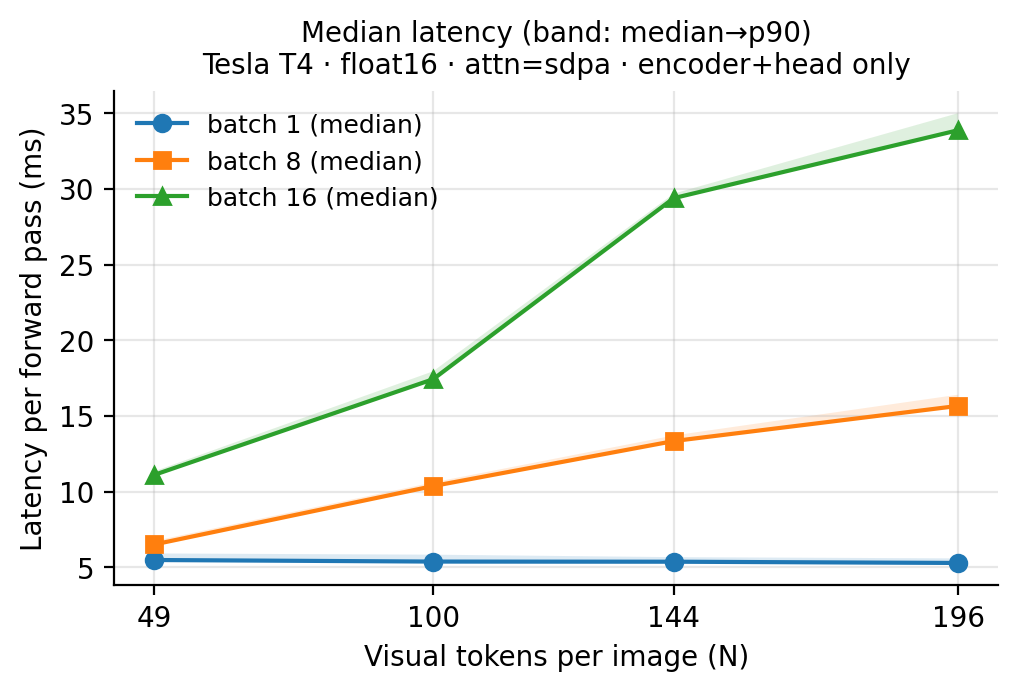

figures/fig2_throughput.png


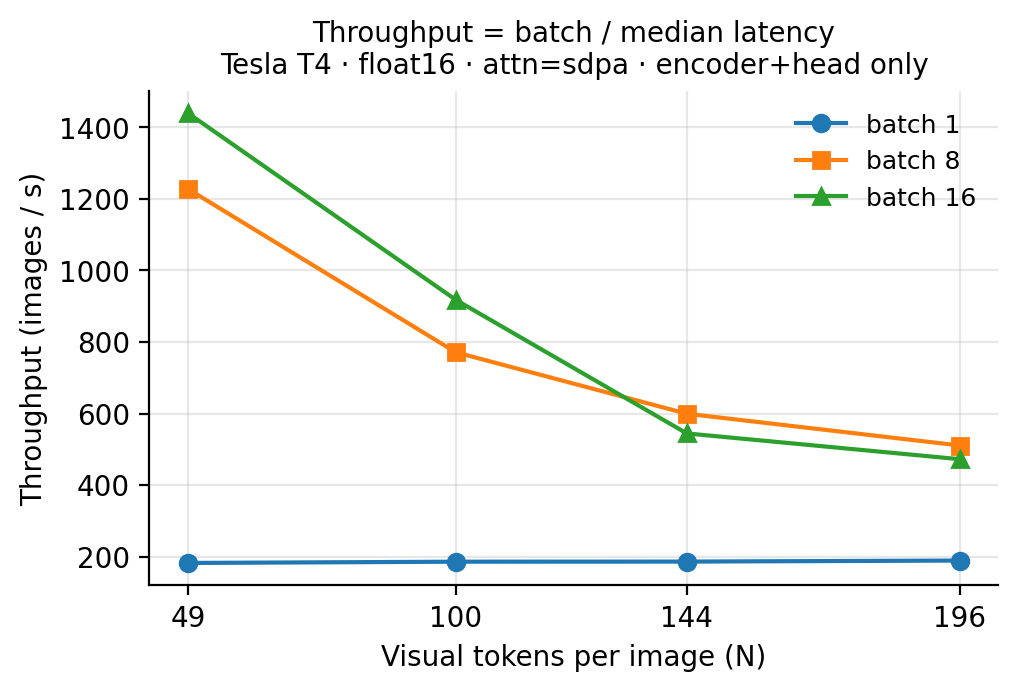

figures/fig3_memory.png


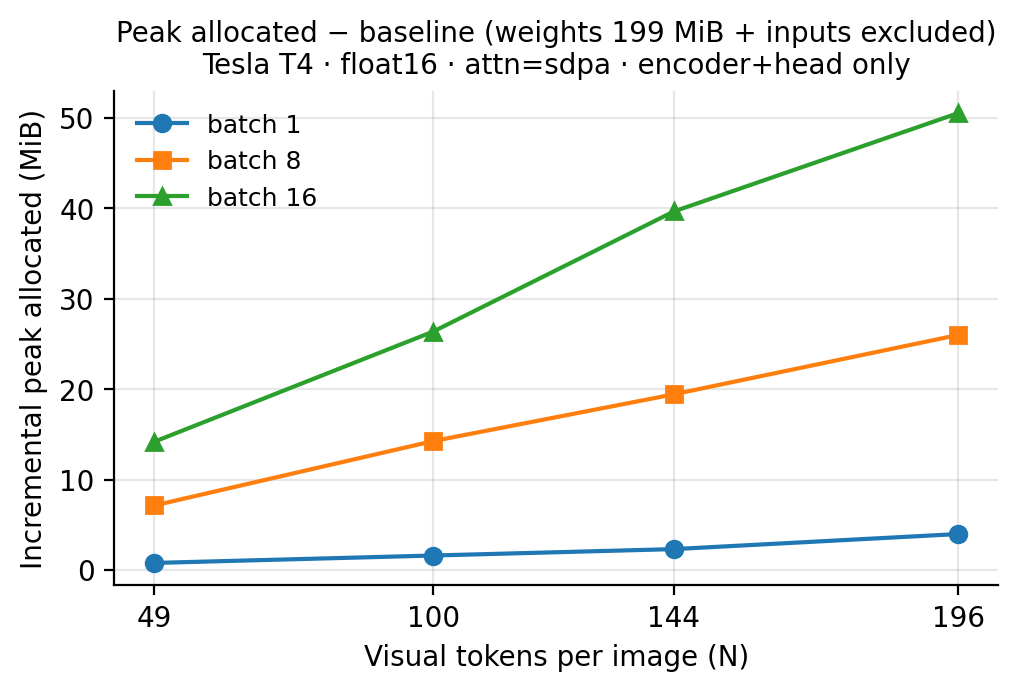

figures/fig4_similarity.png


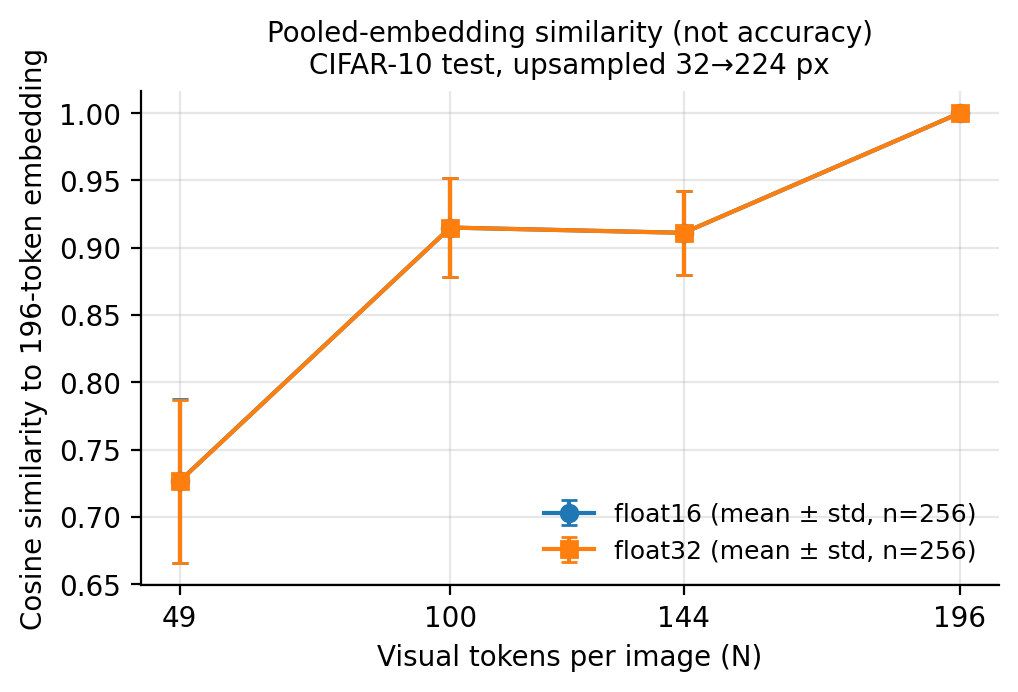

figures/fig5_speedup_vs_theory.png


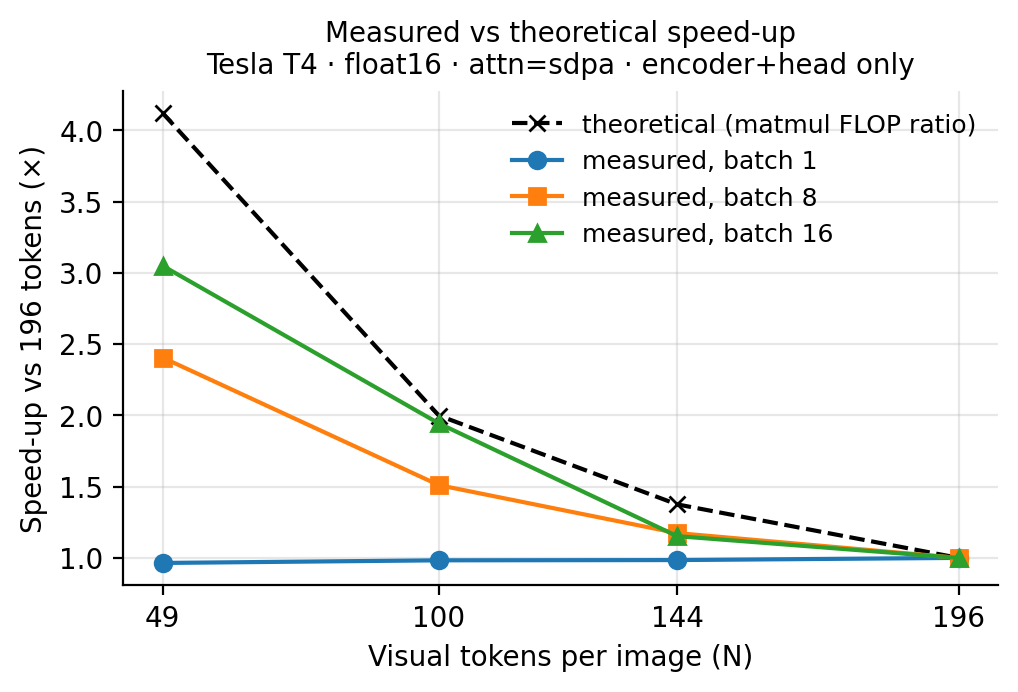

In [14]:
from IPython.display import Image as IPImage, display
for f in sorted(Path("figures").glob("*.png")):
    print(f); display(IPImage(filename=str(f), width=560))

## Step 5 — Experiment E: zero-shot classification accuracy
Full pretrained `SiglipModel`; 10,000 CIFAR-10 test images; prompt `a photo of a {}.` for the 10 classes; text embeddings computed once in FP32 and cached.

1. **Validation gate (FP32):** our 196-token pipeline must reproduce `SiglipModel(input_ids, pixel_values).logits_per_image` (atol 1e-4, rtol 1e-5, 100 % argmax agreement). On failure the cell raises and **no reduced configuration is evaluated**.
2. FP16 image tower, FP32 logits; every configuration sees the same preprocessed batches.
3. Top-1, per-class, Δ vs 196 with paired 95 % bootstrap CIs (10,000 resamples, seed 42), end-to-end classification latency at batch 16 and 64.

`fig7` combines this run's accuracy with Experiment A's encoder-only latency (`results/latency_summary.csv`); if Step 4 has not run in this session, only the end-to-end panel is drawn.

In [15]:
importlib.reload(model_wrapper); importlib.reload(benchmark); importlib.reload(zeroshot)
zs_args = zeroshot.parse_args([
    "--out", str(WORK), "--data-root", str(WORK / "data"),
    "--n-images", "10000", "--batch-size", "128", "--dtype", "float16",
    "--latency-batch-sizes", "16", "64", "--warmup", "10", "--reps", "30",
    "--n-boot", "10000", "--seed", "42",
])
zeroshot.main(zs_args)

[transformers] Model config: bos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49406. This may result in unexpected behavior.
[transformers] Model config: eos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49407. This may result in unexpected behavior.


tokenizer_config.json:   0%|          | 0.00/711 [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  798kB            

spiece.model: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/409 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.40M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/408 [00:00<?, ?it/s]

/kaggle/working/efficient-vit-bench/src/zeroshot.py:369: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  logit_scale = float(model.logit_scale.float().exp())


FP32 image-text logit validation: {
  "n_images": 32,
  "n_prompts": 10,
  "dtype": "torch.float32",
  "logits_shape": [
    32,
    10
  ],
  "max_abs_diff_logits": 1.9073486328125e-06,
  "max_abs_ref_logit": 18.073047637939453,
  "max_abs_diff_image_embeds": 0.0,
  "max_abs_diff_text_embeds": 0.0,
  "argmax_agreement": 1.0,
  "atol": 0.0001,
  "rtol": 1e-05,
  "passed": true
}
  evaluated 128/10000
  evaluated 1408/10000
  evaluated 2688/10000
  evaluated 3968/10000
  evaluated 5248/10000
  evaluated 6528/10000
  evaluated 7808/10000
  evaluated 9088/10000

Measured on **Tesla T4**, Transformers 5.20.2, image tower **float16**, 10000 CIFAR-10 test images, prompt `a photo of a {}.`, run 2026-11-08T15:00:33Z.

Validation (FP32, 32 images × 10 prompts): max |Δ logit| = 1.91e-06 vs `SiglipModel(...).logits_per_image` (|logit| ≤ 18.1, tolerance atol=0.0001, rtol=1e-05), argmax agreement 100% — **passed**.
float16 vs FP32 prediction agreement at 196 tokens: 100.00% on 32 images.

| Tokens 

{
  "logits": {
    "n_images": 32,
    "n_prompts": 10,
    "dtype": "torch.float32",
    "logits_shape": [
      32,
      10
    ],
    "max_abs_diff_logits": 1.9073486328125e-06,
    "max_abs_ref_logit": 18.073047637939453,
    "max_abs_diff_image_embeds": 0.0,
    "max_abs_diff_text_embeds": 0.0,
    "argmax_agreement": 1.0,
    "atol": 0.0001,
    "rtol": 1e-05,
    "passed": true
  },
  "precision_check": {
    "n_images": 32,
    "prediction_agreement": 1.0
  }
}


,num_tokens,n_images,accuracy,accuracy_ci_low,accuracy_ci_high,delta_vs_196,delta_ci_low,delta_ci_high,baseline_right_reduced_wrong,baseline_wrong_reduced_right,cosine_mean,cosine_std
0,196,10000,0.9259,0.9206,0.9311,0.0000,0.0000,0.0000,0,0,1.0000,0.0000
1,144,10000,0.8484,0.8415,0.8554,-0.0775,-0.0840,-0.0711,962,187,0.9105,0.0315
2,100,10000,0.7828,0.7746,0.7910,-0.1431,-0.1508,-0.1356,1582,151,0.9146,0.0364
3,49,10000,0.3128,0.3037,0.3220,-0.6131,-0.6231,-0.6030,6235,104,0.7247,0.0620


num_tokens,49,100,144,196
class_name,,,,
airplane,0.479,0.707,0.782,0.881
automobile,0.433,0.919,0.960,0.974
bird,0.586,0.894,0.906,0.952
cat,0.281,0.816,0.794,0.896
deer,0.054,0.668,0.763,0.875
dog,0.092,0.651,0.746,0.907
frog,0.363,0.700,0.830,0.931
horse,0.219,0.854,0.913,0.950
ship,0.586,0.945,0.976,0.982


,attn_impl,dtype,mode,batch,num_tokens,n,median_ms,mean_ms,std_ms,min_ms,p90_ms,throughput_img_per_s,speedup_vs_196
0,sdpa,float16,zeroshot_end_to_end,16,196,30,40.375,40.282,1.124,37.824,41.528,396.290,1.000
1,sdpa,float16,zeroshot_end_to_end,16,144,30,33.975,33.628,1.515,30.230,35.144,470.929,1.188
2,sdpa,float16,zeroshot_end_to_end,16,100,30,21.957,21.973,0.926,20.466,23.495,728.684,1.839
3,sdpa,float16,zeroshot_end_to_end,16,49,30,15.072,14.926,0.642,13.654,15.582,1061.584,2.679
4,sdpa,float16,zeroshot_end_to_end,64,196,30,186.779,186.750,3.008,180.255,190.321,342.652,1.000
5,sdpa,float16,zeroshot_end_to_end,64,144,30,138.405,138.296,2.464,133.380,140.809,462.411,1.350
6,sdpa,float16,zeroshot_end_to_end,64,100,30,95.430,95.531,1.920,91.518,97.650,670.649,1.957
7,sdpa,float16,zeroshot_end_to_end,64,49,30,53.254,52.662,1.971,49.009,54.725,1201.797,3.507


figures/fig6_zeroshot_accuracy_vs_tokens.png


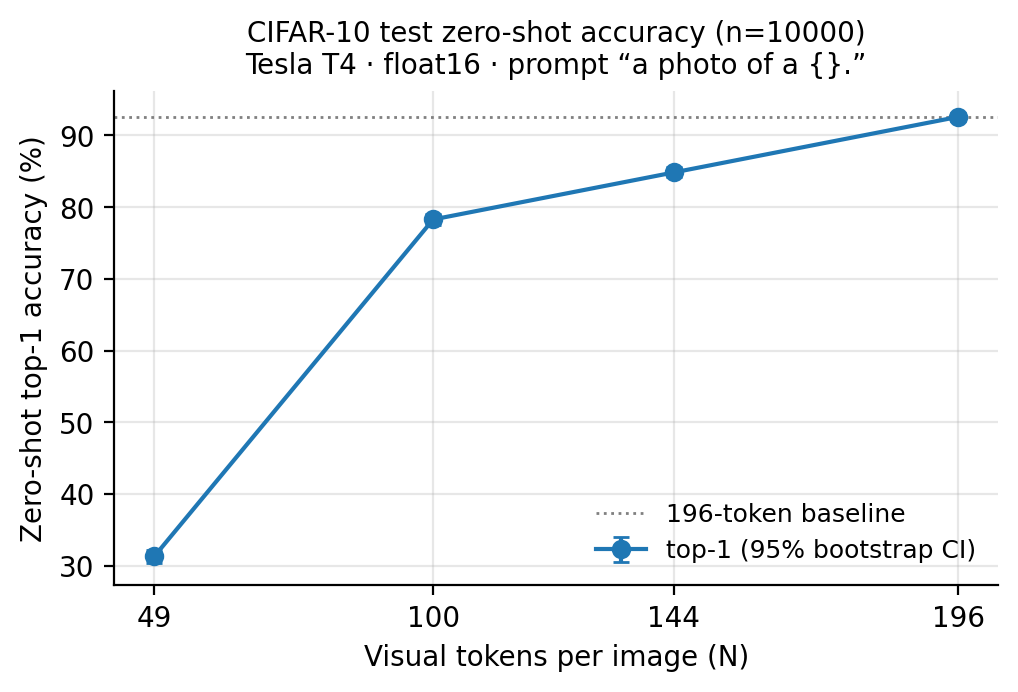

figures/fig7_zeroshot_accuracy_vs_latency.png


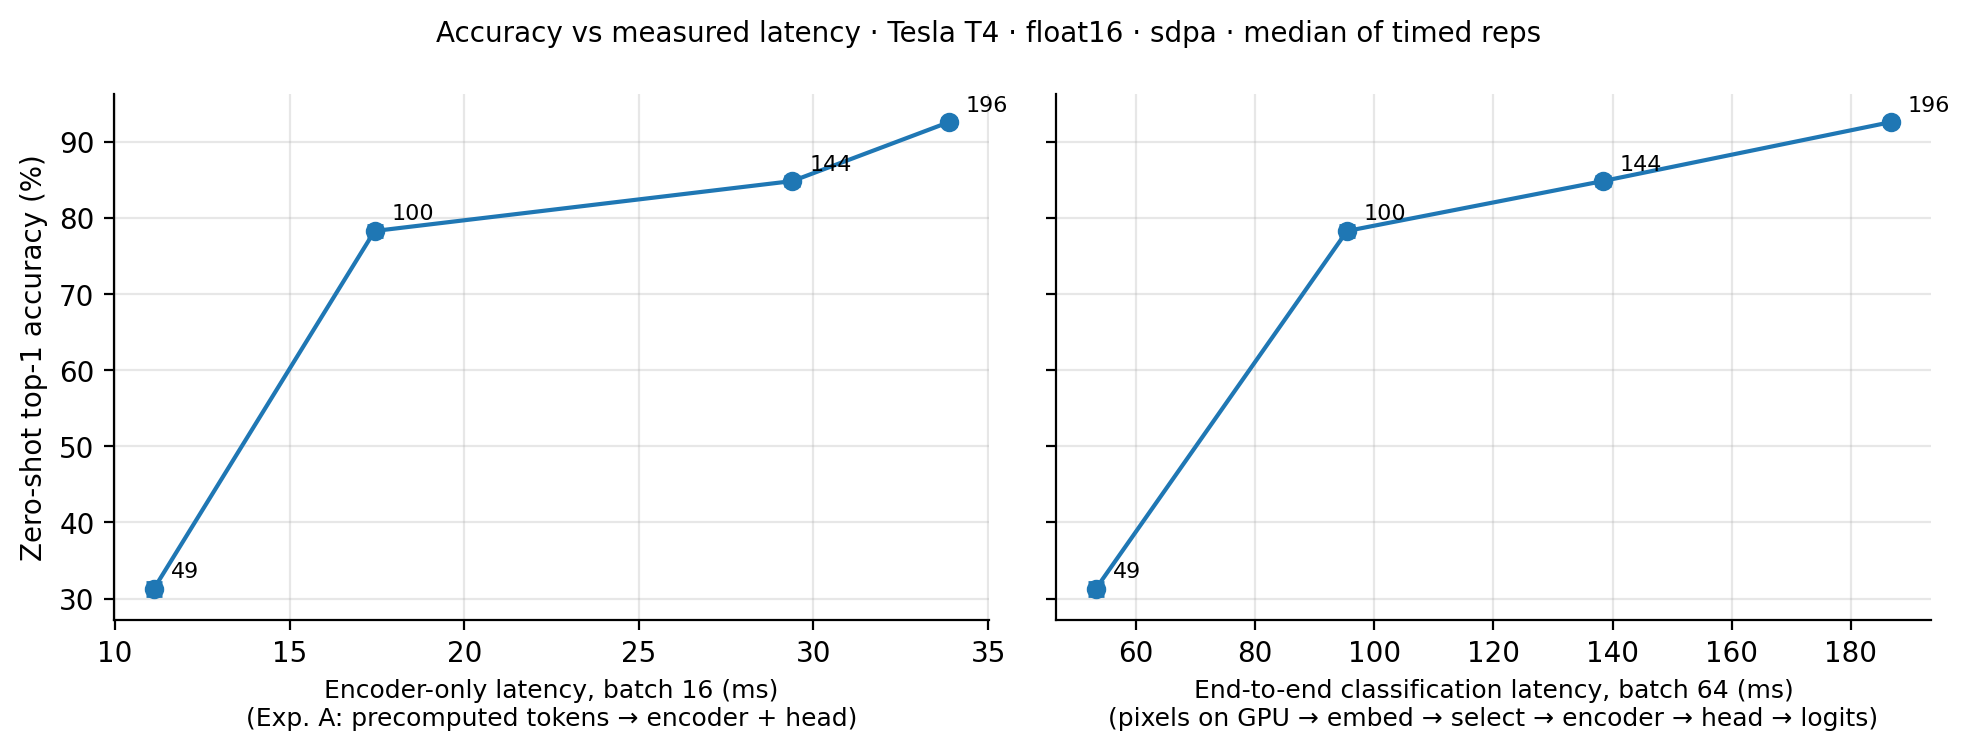

figures/fig8_similarity_vs_accuracy.png


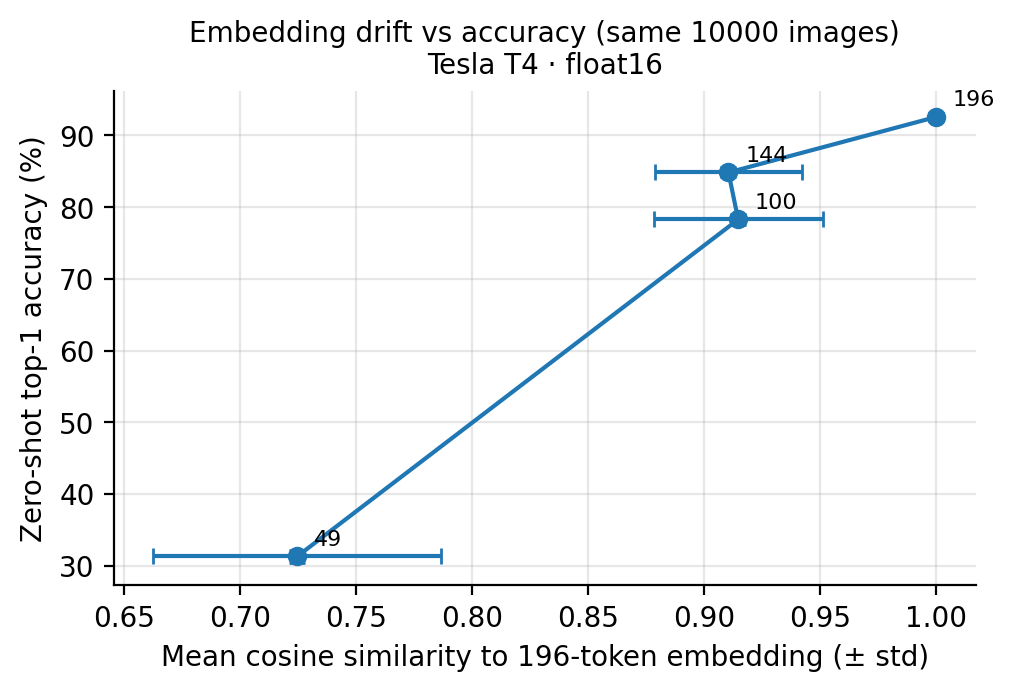

figures/fig9_zeroshot_per_class.png


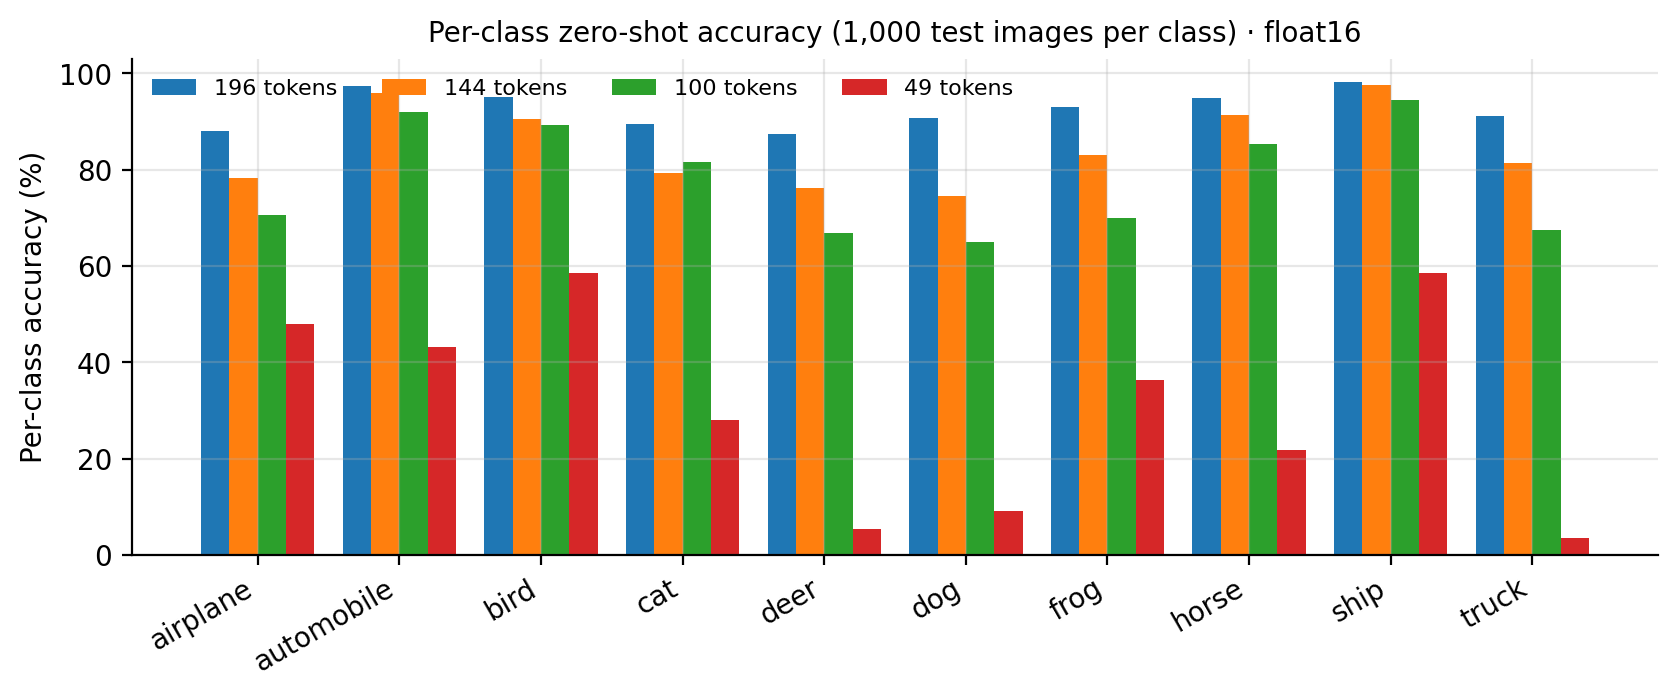

In [16]:
import json
import pandas as pd
print(json.dumps(json.loads(Path("results/zeroshot_validation.json").read_text()), indent=2))
display(pd.read_csv("results/zeroshot_summary.csv").round(4))
pc = pd.read_csv("results/zeroshot_per_class.csv")
display(pc.pivot(index="class_name", columns="num_tokens", values="accuracy").reindex(zeroshot.CIFAR10_CLASSES).round(3))
display(pd.read_csv("results/zeroshot_latency_summary.csv").round(3))
from IPython.display import Image as IPImage, display
for f in sorted(Path("figures").glob("fig[6-9]_*.png")):
    print(f); display(IPImage(filename=str(f), width=640))

## Fill the README results sections and package the outputs

In [17]:
# Re-render every results section that has data in results/ (safe to rerun after the README cell)
if Path("results/latency_summary.csv").exists():
    benchmark.fill_readme(WORK / "README.md", WORK / "results")
if Path("results/zeroshot_summary.csv").exists():
    zeroshot.fill_readme(WORK / "README.md", WORK / "results")
import zipfile
zip_path = WORK.parent / "efficient-vit-bench-results.zip"
keep = {"src", "results", "figures", "README.md", "requirements.txt"}
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:   # project files only, not the CIFAR download
    for f in sorted(WORK.rglob("*")):
        rel = f.relative_to(WORK)
        if f.is_file() and rel.parts[0] in keep and "__pycache__" not in rel.parts:
            z.write(f, Path(WORK.name) / rel)
print("Download:", zip_path, f"({zip_path.stat().st_size / 1e6:.1f} MB)")
print(Path("results/environment.json").read_text())

README results section updated from /kaggle/working/efficient-vit-bench/results
README zero-shot section updated from /kaggle/working/efficient-vit-bench/results
Download: /kaggle/working/efficient-vit-bench-results.zip (2.0 MB)
{
  "timestamp_utc": "2026-11-08T14:59:07Z",
  "python": "3.13.16",
  "platform": "Linux-6.18.55+-x86_64-with-glibc2.39",
  "torch": "2.11.0+cu130",
  "transformers": "5.20.2",
  "numpy": "2.1.3",
  "cuda_available": true,
  "torch_cuda_build": "13.0",
  "cudnn": 92700,
  "device": "cuda:0",
  "gpu_name": "Tesla T4",
  "gpu_total_memory_mib": 14911.6875,
  "gpu_compute_capability": "7.5",
  "gpu_multiprocessors": 40,
  "gpu_count_visible": 2,
  "nvidia_smi": "name, driver_version, clocks.current.sm [MHz], clocks.max.sm [MHz], clocks.current.memory [MHz], power.limit [W], temperature.gpu\nTesla T4, 580.178.04, 1455 MHz, 1590 MHz, 5000 MHz, 70.00 W, 59\nTesla T4, 580.178.04, 300 MHz, 1590 MHz, 405 MHz, 70.00 W, 54",
  "nvidia_smi_after": "name, driver_version, cl